Loaded file: fix_probs_WF.Nruns20000_N100_M3_D10.npy
Loaded file: fix_probs_expansion.N100_M3_D10.npy


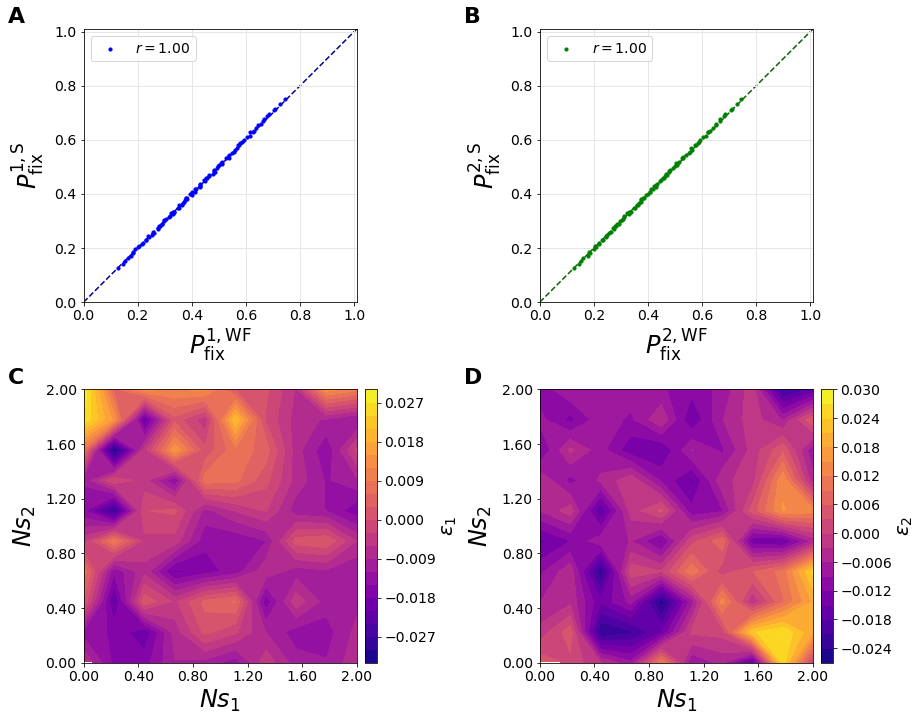

In [44]:
### M=3 plots for P_fix comparisons           ###
### WF vs. expansion + Langevin vs. expansion ###

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

import os

### Load data: ###

Nruns = 20000 # total number of runs for computing fixation probabilities for a given combination of fitnesses
N = 100 # total number of individuals in the population
M = 3 # total number of genotypes
D = 10 # total number of points per fitness range

folder = "data_fix_prob"
#folder = "./"

#f1 = f"fix_probs_Langevin.Nruns{Nruns}_N{N}_M{M}_D{D}.npy" # Langevin simulations
f1 = f"fix_probs_WF.Nruns{Nruns}_N{N}_M{M}_D{D}.npy" # WF simulations

f2 = f"fix_probs_expansion.N{N}_M{M}_D{D}.npy" # perturbative expansion

#fout = f"fix_probs_Langevin_expansion.Nruns{Nruns}_N{N}_M{M}_D{D}.pdf"
fout = f"fix_probs_WF_expansion.Nruns{Nruns}_N{N}_M{M}_D{D}.pdf"

fout = os.path.join(folder,fout)

# Re-create selection arrays used in the simulations:
eps = 1e-05 # s = 0.0 does not work in Kimura's formula
SMAX = 0.02
sel_coeff = np.linspace(0.0, SMAX, num=D) + eps

fix_probs_1 = np.load(os.path.join(folder,f1))
fix_probs_2 = np.load(os.path.join(folder,f2))

#####
print("Loaded file:",f1)
print("Loaded file:",f2)

p1_f1 = fix_probs_1[:,:,0] # 2D arrays
p2_f1 = fix_probs_1[:,:,1]

p1_f2 = fix_probs_2[:,:,0] # 2D arrays
p2_f2 = fix_probs_2[:,:,1]

r1 = np.corrcoef(p1_f1.flatten(), p1_f2.flatten())[0,1]
r2 = np.corrcoef(p2_f1.flatten(), p2_f2.flatten())[0,1]


assert M==3, f"Illegal M={M} in plotting!"


#####################

# -----------------------------
# Style parameters
# -----------------------------
params = {
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "figure.figsize": [14.0, 10.0],
}
plt.rcParams.update(params)

# -----------------------------
# Derived quantities
# -----------------------------
eps1 = np.divide(
    p1_f1 - p1_f2,
    p1_f1,
    out=np.full_like(p1_f1, np.nan, dtype=float),
    where=p1_f1 != 0
)

eps2 = np.divide(
    p2_f1 - p2_f2,
    p2_f1,
    out=np.full_like(p2_f1, np.nan, dtype=float),
    where=p2_f1 != 0
)

Ns = N * sel_coeff
#Ns_min = np.min(Ns)
#Ns_max = np.max(Ns)
Ns_min = 0.0
Ns_max = N * SMAX

# -----------------------------
# Common ticks and formatters
# -----------------------------
prob_ticks = np.linspace(0.0, 1.0, 6)
prob_formatter = FormatStrFormatter("%.1f")

use_integer_Ns_ticks = np.allclose(Ns, np.round(Ns))

Ns_locator = MaxNLocator(nbins=5, integer=use_integer_Ns_ticks)
Ns_ticks = Ns_locator.tick_values(Ns_min, Ns_max)
Ns_ticks = Ns_ticks[(Ns_ticks >= Ns_min) & (Ns_ticks <= Ns_max)]

if use_integer_Ns_ticks:
    Ns_formatter = FormatStrFormatter("%d")
else:
    Ns_formatter = FormatStrFormatter("%.2f")

# -----------------------------
# Figure layout
# -----------------------------
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Leave enough space between columns for the left colorbar
# and enough right margin for the right colorbar
fig.subplots_adjust(
    left=0.08,
    right=0.92,
    bottom=0.08,
    top=0.96,
    wspace=0.35,
    hspace=0.32
)

ax11 = axs[0, 0]
ax12 = axs[0, 1]
ax21 = axs[1, 0]
ax22 = axs[1, 1]

dx = 0.03

for ax in [ax12, ax22]:
    pos = ax.get_position()
    ax.set_position([
        pos.x0 - dx,
        pos.y0,
        pos.width,
        pos.height
    ])

# Colorbar placement parameters
# cbar_pad controls the gap between plot and colorbar.
# Decrease to 0.01 for even closer colorbars.
cbar_pad = 0.03
cbar_width = 0.045

# =========================================================
# Panel (1,1): p1 scatter
# =========================================================
ax = ax11

ax.grid(color="0.9", linestyle="-", linewidth=1, zorder=0)

ax.scatter(
    p1_f1.flatten(),
    p1_f2.flatten(),
    c="blue",
    s=10,
    label=fr"$r={r1:.2f}$",
    zorder=2
)

ax.axline((0, 0), slope=1, color="darkblue", linestyle="--", zorder=1)

#ax.set_xlabel(r"$P_\mathrm{fix}^{1,\mathrm{L}}$", fontsize=24)
ax.set_xlabel(r"$P_\mathrm{fix}^{1,\mathrm{WF}}$", fontsize=24)
ax.set_ylabel(r"$P_\mathrm{fix}^{1,\mathrm{S}}$", fontsize=24, labelpad=8)

ax.set_xlim(0.0, 1.01)
ax.set_ylim(0.0, 1.01)

ax.set_xticks(prob_ticks)
ax.set_yticks(prob_ticks)
ax.xaxis.set_major_formatter(prob_formatter)
ax.yaxis.set_major_formatter(prob_formatter)

ax.set_aspect("equal", adjustable="box")
ax.legend(loc="best")

# =========================================================
# Panel (1,2): p2 scatter
# =========================================================
ax = ax12

ax.grid(color="0.9", linestyle="-", linewidth=1, zorder=0)

ax.scatter(
    p2_f1.flatten(),
    p2_f2.flatten(),
    c="green",
    s=10,
    label=fr"$r={r2:.2f}$",
    zorder=2
)

ax.axline((0, 0), slope=1, color="darkgreen", linestyle="--", zorder=1)

#ax.set_xlabel(r"$P_\mathrm{fix}^{2,\mathrm{L}}$", fontsize=24)
ax.set_xlabel(r"$P_\mathrm{fix}^{2,\mathrm{WF}}$", fontsize=24)
ax.set_ylabel(r"$P_\mathrm{fix}^{2,\mathrm{S}}$", fontsize=24, labelpad=8)

ax.set_xlim(0.0, 1.01)
ax.set_ylim(0.0, 1.01)

ax.set_xticks(prob_ticks)
ax.set_yticks(prob_ticks)
ax.xaxis.set_major_formatter(prob_formatter)
ax.yaxis.set_major_formatter(prob_formatter)

ax.set_aspect("equal", adjustable="box")
ax.legend(loc="best")

# =========================================================
# Panel (2,1): contour of epsilon for p1
# =========================================================
ax = ax21

cf1 = ax.contourf(
    Ns,
    Ns,
    eps1.T,
    levels=20,
    cmap="plasma"
)

ax.set_xlabel(r"$N s_1$", fontsize=24)
ax.set_ylabel(r"$N s_2$", fontsize=24, labelpad=8)

ax.set_xlim(Ns_min, Ns_max)
ax.set_ylim(Ns_min, Ns_max)

ax.set_xticks(Ns_ticks)
ax.set_yticks(Ns_ticks)
ax.xaxis.set_major_formatter(Ns_formatter)
ax.yaxis.set_major_formatter(Ns_formatter)

ax.set_aspect("equal", adjustable="box")

# Attach colorbar directly to the visible plot box
cax1 = ax.inset_axes(
    [1.0 + cbar_pad, 0.0, cbar_width, 1.0],
    transform=ax.transAxes
)

cbar1 = fig.colorbar(cf1, cax=cax1)
cbar1.set_label(r"$\varepsilon_1$", size=20)

# =========================================================
# Panel (2,2): contour of epsilon for p2
# =========================================================
ax = ax22

cf2 = ax.contourf(
    Ns,
    Ns,
    eps2.T,
    levels=20,
    cmap="plasma"
)

ax.set_xlabel(r"$N s_1$", fontsize=24)
ax.set_ylabel(r"$N s_2$", fontsize=24, labelpad=8)

ax.set_xlim(Ns_min, Ns_max)
ax.set_ylim(Ns_min, Ns_max)

ax.set_xticks(Ns_ticks)
ax.set_yticks(Ns_ticks)
ax.xaxis.set_major_formatter(Ns_formatter)
ax.yaxis.set_major_formatter(Ns_formatter)

ax.set_aspect("equal", adjustable="box")

# Attach colorbar directly to the visible plot box
cax2 = ax.inset_axes(
    [1.0 + cbar_pad, 0.0, cbar_width, 1.0],
    transform=ax.transAxes
)

cbar2 = fig.colorbar(cf2, cax=cax2)
cbar2.set_label(r"$\varepsilon_2$", size=20)

# -----------------------------
# Panel labels
# -----------------------------
panel_labels = {
    ax11: r"$\mathbf{A}$",
    ax12: r"$\mathbf{B}$",
    ax21: r"$\mathbf{C}$",
    ax22: r"$\mathbf{D}$",
}

for ax, label in panel_labels.items():
    ax.text(
        -0.28, 1.08,
        label,
        transform=ax.transAxes,
        fontsize=22,
        fontweight="bold",
        va="top",
        ha="left"
    )


plt.savefig(fout, bbox_inches='tight')

plt.show()

###################


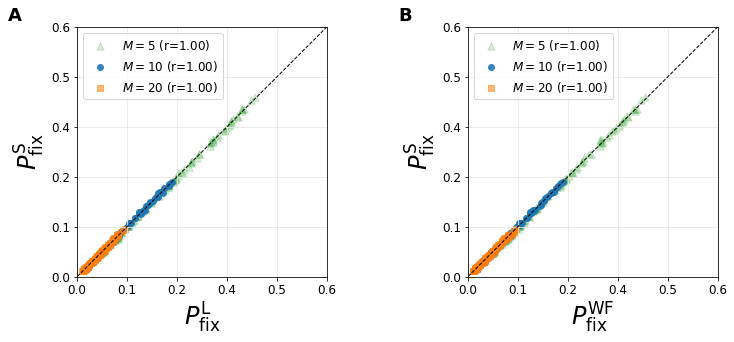

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

import os

### Load data: ###

folder = "data_fix_prob"
#folder = "./"

# -----------------------------
# File lists
# -----------------------------
# Langevin (rsets)
fL = [
    "fix_probs_Langevin_rsets.Nruns20000_N100_M5_D20.npy",
    "fix_probs_Langevin_rsets.Nruns20000_N100_M10_D10.npy",
    "fix_probs_Langevin_rsets.Nruns20000_N100_M20_D5.npy"
]

# WF (rsets)
fW = [
    "fix_probs_WF_rsets.Nruns20000_N100_M5_D20.npy",
    "fix_probs_WF_rsets.Nruns20000_N100_M10_D10.npy",
    "fix_probs_WF_rsets.Nruns20000_N100_M20_D5.npy"
]

# Series expansion (rsets)
fE = [
    "fix_probs_expansion_rsets.N100_M5_D20.npy",
    "fix_probs_expansion_rsets.N100_M10_D10.npy",
    "fix_probs_expansion_rsets.N100_M20_D5.npy"
]

# -----------------------------
# Labels, markers, colors
# -----------------------------
#labels = [
#    r"$M=10,\ D=10$",
#    r"$M=20,\ D=5$",
#    r"$M=5,\ D=20$"
#]
labels = [
    r"$M=5$",
    r"$M=10$",
    r"$M=20$"
]

markers = ["^", "o", "s"]
colors  = ["tab:green", "tab:blue", "tab:orange"]
alphas = [0.20, 0.90, 0.55]
sizes = [55, 35, 45]

# -----------------------------
# Plot style
# -----------------------------
params = {
    "axes.labelsize": 16,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.figsize": [12, 5]
}
plt.rcParams.update(params)

# -----------------------------
# Create figure
# -----------------------------
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

prob_ticks = np.linspace(0.0, 0.6, 6)
prob_formatter = FormatStrFormatter("%.1f")

# =============================
# Left panel: Langevin vs expansion
# =============================
ax = axs[0]

for f1, f2, lab, mk, col, size, alpha in zip(fL, fE, labels, markers, colors, sizes, alphas):
    x = np.load(os.path.join(folder,f1)).flatten()
    y = np.load(os.path.join(folder,f2)).flatten()
    r = np.corrcoef(x, y)[0,1]
    ax.scatter(
        x, y,
        s=size,
        marker=mk,
        color=col,
        label=f"{lab} (r={r:.2f})",
        alpha=alpha
    )

ax.axline((0, 0), slope=1, color="black", linestyle="--", linewidth=1)

ax.set_xlabel(r"$P_{\mathrm{fix}}^{\mathrm{L}}$", fontsize=24)
ax.set_ylabel(r"$P_{\mathrm{fix}}^{\mathrm{S}}$", fontsize=24)
ax.grid(True, color="0.9")
ax.legend(loc="best")

ax.set_xlim(0, 0.6)
ax.set_ylim(0, 0.6)
ax.set_xticks(prob_ticks)
ax.set_yticks(prob_ticks)
ax.xaxis.set_major_formatter(prob_formatter)
ax.yaxis.set_major_formatter(prob_formatter)
ax.set_aspect("equal", adjustable="box")

# panel label
ax.text(
    -0.28, 1.08, r"$\mathbf{A}$",
    transform=ax.transAxes,
    fontsize=18,
    va="top",
    ha="left"
)

# =============================
# Right panel: WF vs expansion
# =============================
ax = axs[1]

for f1, f2, lab, mk, col, size, alpha in zip(fW, fE, labels, markers, colors, sizes, alphas):
    x = np.load(os.path.join(folder,f1)).flatten()
    y = np.load(os.path.join(folder,f2)).flatten()
    r = np.corrcoef(x, y)[0,1]
    ax.scatter(
        x, y,
        s=size,
        marker=mk,
        color=col,
        label=f"{lab} (r={r:.2f})",
        alpha=alpha
    )

ax.axline((0, 0), slope=1, color="black", linestyle="--", linewidth=1)

ax.set_xlabel(r"$P_{\mathrm{fix}}^{\mathrm{WF}}$", fontsize=24)
ax.set_ylabel(r"$P_{\mathrm{fix}}^{\mathrm{S}}$", fontsize=24)
ax.grid(True, color="0.9")
ax.legend(loc="best")

ax.set_xlim(0, 0.6)
ax.set_ylim(0, 0.6)
ax.set_xticks(prob_ticks)
ax.set_yticks(prob_ticks)
ax.xaxis.set_major_formatter(prob_formatter)
ax.yaxis.set_major_formatter(prob_formatter)
ax.set_aspect("equal", adjustable="box")

# panel label
ax.text(
    -0.28, 1.08, r"$\mathbf{B}$",
    transform=ax.transAxes,
    fontsize=18,
    va="top",
    ha="left"
)

plt.tight_layout(w_pad=0.8)
fig.subplots_adjust(wspace=0.02)

######
fout = "fix_probs_Langevin_WF_expansion.mult_runs.pdf"
fout = os.path.join(folder,fout)

plt.savefig(fout, bbox_inches='tight')

plt.show()


<Flux> = 1.0000
std(Flux) = 0.0000

<Flux> = 1.0000
std(Flux) = 0.0000

<Flux> = 1.0000
std(Flux) = 0.0000

<Flux> = 1.0000
std(Flux) = 0.0000



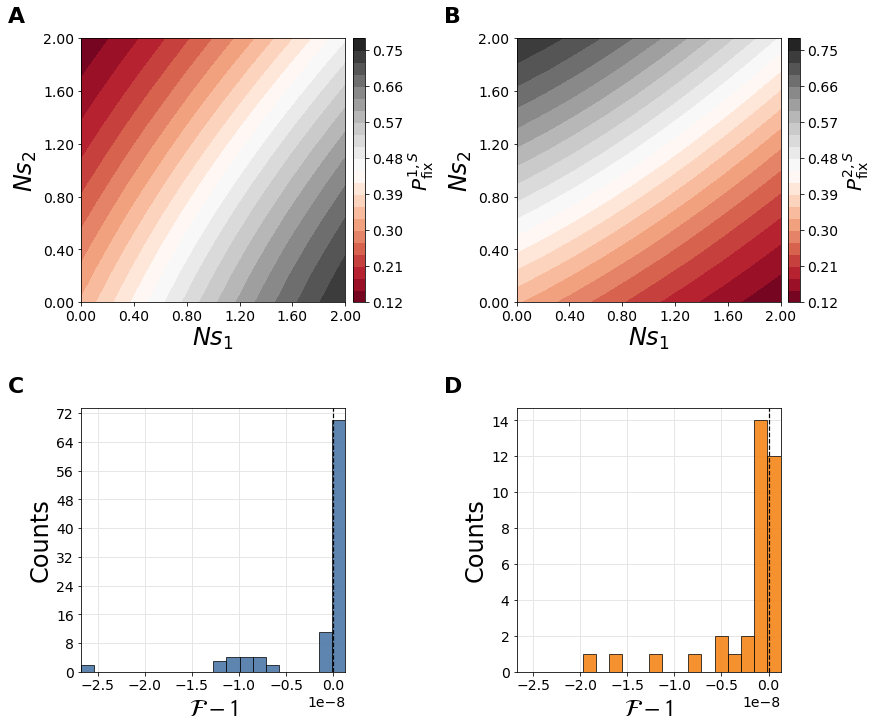

In [47]:
### Series expansion fixation probabilities and the fluctuation theorem constraint ###

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from matplotlib.ticker import MaxNLocator

import os

#######
# M=3, DxD scan over selection coeff.
def get_flux_M3(fix_probs, init_freqs, D, N):
    
    # Re-create selection coeff.:
    eps = 1e-05 # s = 0.0 does not work in Kimura's formula
    SMAX = 0.02
    sel_coeff = np.linspace(0.0, SMAX, num=D) + eps
    
    # Set up fixation probs:
    p1f = fix_probs[:, :, 0] # 2D arrays, no_transpose
    p2f = fix_probs[:, :, 1]
    
    sum_of_fluxes = np.zeros((D,D))
    
    for i in range(D):
        si = sel_coeff[i]
        for j in range(D):
            sj = sel_coeff[j]
            istate = si*init_freqs[0] + sj*init_freqs[1]
            ######
            #sum_of_fluxes[i,j] = p1f[i,j] * np.exp(-2*N*(si-istate)) + p2f[i,j] * np.exp(-2*N*(sj-istate)) + \
            #         (1-p1f[i,j]-p2f[i,j]) * np.exp(2*N*istate)
            sum_of_fluxes[i,j] = np.exp(-2*N*istate) - \
                                (np.exp(-2*N*si) - 1)*p1f[i,j] - (np.exp(-2*N*sj) - 1)*p2f[i,j]
    
    print("<Flux> = {:.4f}".format(np.mean(sum_of_fluxes)))
    print("std(Flux) = {:.4f}\n".format(np.std(sum_of_fluxes)))
    
    return sum_of_fluxes - 1.0 # subtract 1.0 from the constraint

        
#######
# Arbitrary M, D sets of selection coeff.
def get_flux_rsets(fix_probs, init_freqs, sel_coeff, N):
    
    D = sel_coeff.shape[0]
    M = sel_coeff.shape[1] + 1
    
    sum_of_fluxes = np.zeros(D)
    
    for i in range(D):
        ######
        istate = 0.0
        for j in range(M-1):
            istate += sel_coeff[i,j]*init_freqs[j]

        ######
        sum_of_fluxes[i] = np.exp(-2*N*istate)
        for j in range(M-1):
            sum_of_fluxes[i] -= (np.exp(-2*N*sel_coeff[i,j]) - 1)*fix_probs[i,j]

    print("<Flux> = {:.4f}".format(np.mean(sum_of_fluxes)))
    print("std(Flux) = {:.4f}\n".format(np.std(sum_of_fluxes)))
    
    return sum_of_fluxes - 1.0 # subtract 1.0 from the constraint

################################

### Load data: ###

N = 100 # total number of individuals in the population
#Ds = [10, 10, 5, 20]
D_M3 = 10
Ms = [3, 10, 20, 5]

folder = "data_fix_prob"
#folder = "./"

# Series expansion (M=3 + rsets)
fE = [
    "fix_probs_expansion.N100_M3_D10.npy",
    "fix_probs_expansion_rsets.N100_M10_D10.npy",
    "fix_probs_expansion_rsets.N100_M20_D5.npy",
    "fix_probs_expansion_rsets.N100_M5_D20.npy"
]

#x0 = [
#    "fix_probs_expansion.N100_M3_D10.x0.txt",
#    "fix_probs_expansion_rsets.N100_M10_D10.x0.txt",
#    "fix_probs_expansion_rsets.N100_M20_D5.x0.txt",
#    "fix_probs_expansion_rsets.N100_M5_D20.x0.txt"
#]

sel = [
    "none",
    "sel_coeff_expansion_rsets.N100_M10_D10.npy",
    "sel_coeff_expansion_rsets.N100_M20_D5.npy",
    "sel_coeff_expansion_rsets.N100_M5_D20.npy"
]

# Compute flux constraints:

# M=3 scan:
fix_probs_M3 = np.load(os.path.join(folder,fE[0]))
init_freqs_M3 = np.ones(Ms[0]) / Ms[0] # uniform freqs
#init_freqs_M3 = np.loadtxt(os.path.join(folder,x0[0]))
####
p1f = fix_probs_M3[:, :, 0] # 2D arrays, no_transpose
p2f = fix_probs_M3[:, :, 1]

fluxes_M3 = get_flux_M3(fix_probs_M3, init_freqs_M3, D_M3, N)

# Arbitrary M flux constraints:
fluxes_rsets = []
for j in range(1,len(fE)):
    fprobs = np.load(os.path.join(folder,fE[j]))
    ifreqs = np.ones(Ms[j]) / Ms[j] # uniform freqs
    #ifreqs = np.loadtxt(os.path.join(folder,x0[j]))
    scoeffs = np.load(os.path.join(folder,sel[j]))
    ######
    fluxes_rsets.append(get_flux_rsets(fprobs, ifreqs, scoeffs, N))

#####################

# =========================================================
# Plotting
# =========================================================

# -----------------------------
# Style parameters
# -----------------------------
params = {
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "figure.figsize": [14.0, 10.0],
}
plt.rcParams.update(params)

# -----------------------------
# Re-create selection coefficients for M=3 scan
# -----------------------------
eps = 1e-05
SMAX = 0.02
sel_coeff = np.linspace(0.0, SMAX, num=D_M3) + eps

Ns = N * sel_coeff
#Ns_min = np.min(Ns)
#Ns_max = np.max(Ns)
Ns_min = 0.0
Ns_max = N * SMAX

# Concatenate fluxes from arbitrary-M rsets
flux_cat = np.concatenate(fluxes_rsets)

# -----------------------------
# Histogram bins
# -----------------------------
all_flux = np.concatenate((fluxes_M3.flatten(), flux_cat.flatten()))

fmin = np.min(all_flux)
fmax = np.max(all_flux)

pad = 0.05 * (fmax - fmin if fmax > fmin else 1.0)

hist_range = (fmin - pad, fmax + pad)
nbins = 20
hist_bins = np.linspace(hist_range[0], hist_range[1], nbins + 1)

# -----------------------------
# Ticks and formatters
# -----------------------------
use_integer_Ns_ticks = np.allclose(Ns, np.round(Ns))

Ns_locator = MaxNLocator(nbins=5, integer=use_integer_Ns_ticks)
Ns_ticks = Ns_locator.tick_values(Ns_min, Ns_max)
Ns_ticks = Ns_ticks[(Ns_ticks >= Ns_min) & (Ns_ticks <= Ns_max)]

if use_integer_Ns_ticks:
    Ns_formatter = FormatStrFormatter("%d")
else:
    Ns_formatter = FormatStrFormatter("%.2f")

# -----------------------------
# Figure layout
# -----------------------------
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

fig.subplots_adjust(
    left=0.08,
    right=0.90,     # leaves room for right colorbar
    bottom=0.08,
    top=0.96,
    wspace=0.50,    # leaves room between columns for left colorbar
    hspace=0.40
)

ax11 = axs[0, 0]   # (a) p1 contour
ax12 = axs[0, 1]   # (b) p2 contour
ax21 = axs[1, 0]   # (c) M=3 histogram
ax22 = axs[1, 1]   # (d) rsets histogram

dx = 0.06

for ax in [ax12, ax22]:
    pos = ax.get_position()
    ax.set_position([
        pos.x0 - dx,
        pos.y0,
        pos.width,
        pos.height
    ])

# Colorbar placement relative to contour panels
cbar_pad = 0.03
cbar_width = 0.045

# Better histogram palette: colorblind-friendly
hist_color_M3 = "#4C78A8"      # muted blue
hist_color_rsets = "#F58518"   # muted orange


# =========================================================
# Panel (a): contour of p1
# =========================================================
ax = ax11

cf1 = ax.contourf(
    Ns,
    Ns,
    p1f.T,
    levels=20,
    cmap="RdGy"
)

ax.set_xlabel(r"$N s_1$", fontsize=24, labelpad=2)
ax.set_ylabel(r"$N s_2$", fontsize=24, labelpad=4)

ax.set_xlim(Ns_min, Ns_max)
ax.set_ylim(Ns_min, Ns_max)

ax.set_xticks(Ns_ticks)
ax.set_yticks(Ns_ticks)
ax.xaxis.set_major_formatter(Ns_formatter)
ax.yaxis.set_major_formatter(Ns_formatter)

ax.set_aspect("equal", adjustable="box")
ax.set_box_aspect(1)

# Colorbar as inset, so it does not change panel size
cax1 = ax.inset_axes(
    [1.0 + cbar_pad, 0.0, cbar_width, 1.0],
    transform=ax.transAxes
)

cbar1 = fig.colorbar(cf1, cax=cax1)
cbar1.set_label(r"$P_\mathrm{fix}^{1,S}$", size=20)


# =========================================================
# Panel (b): contour of p2
# =========================================================
ax = ax12

cf2 = ax.contourf(
    Ns,
    Ns,
    p2f.T,
    levels=20,
    cmap="RdGy"
)

ax.set_xlabel(r"$N s_1$", fontsize=24, labelpad=2)
ax.set_ylabel(r"$N s_2$", fontsize=24, labelpad=4)

ax.set_xlim(Ns_min, Ns_max)
ax.set_ylim(Ns_min, Ns_max)

ax.set_xticks(Ns_ticks)
ax.set_yticks(Ns_ticks)
ax.xaxis.set_major_formatter(Ns_formatter)
ax.yaxis.set_major_formatter(Ns_formatter)

ax.set_aspect("equal", adjustable="box")
ax.set_box_aspect(1)

# Colorbar as inset, so it does not change panel size
cax2 = ax.inset_axes(
    [1.0 + cbar_pad, 0.0, cbar_width, 1.0],
    transform=ax.transAxes
)

cbar2 = fig.colorbar(cf2, cax=cax2)
cbar2.set_label(r"$P_\mathrm{fix}^{2,S}$", size=20)


# =========================================================
# Panel (c): histogram of flux constraints, M=3
# =========================================================
ax = ax21

ax.grid(color="0.9", linestyle="-", linewidth=1, zorder=0)

ax.hist(
    fluxes_M3.flatten(),
    bins=hist_bins,
    density=False,
    color=hist_color_M3,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    zorder=2
)

ax.axvline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    zorder=3
)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_xlabel(r"$\mathcal{F - 1}$", fontsize=24, labelpad=4)
ax.set_ylabel("Counts", fontsize=24)

ax.set_xlim(hist_range)

# Do NOT use equal data aspect for histograms
ax.set_aspect("auto")

# But make the physical panel box square
ax.set_box_aspect(1)


# =========================================================
# Panel (d): histogram of flux constraints, arbitrary M
# =========================================================
ax = ax22

ax.grid(color="0.9", linestyle="-", linewidth=1, zorder=0)

ax.hist(
    flux_cat.flatten(),
    bins=hist_bins,
    density=False,
    color=hist_color_rsets,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    zorder=2
)

ax.axvline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    zorder=3
)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_xlabel(r"$\mathcal{F - 1}$", fontsize=24, labelpad=4)
ax.set_ylabel("Counts", fontsize=24)

ax.set_xlim(hist_range)

# Do NOT use equal data aspect for histograms
ax.set_aspect("auto")

# But make the physical panel box square
ax.set_box_aspect(1)


# -----------------------------
# Match histogram y-limits
# -----------------------------
#ymax = max(ax21.get_ylim()[1], ax22.get_ylim()[1])
#ax21.set_ylim(0, ymax)
#ax22.set_ylim(0, ymax)


# -----------------------------
# Panel labels
# -----------------------------
panel_labels = {
    ax11: r"$\mathbf{A}$",
    ax12: r"$\mathbf{B}$",
    ax21: r"$\mathbf{C}$",
    ax22: r"$\mathbf{D}$",
}

for ax, label in panel_labels.items():
    ax.text(
        -0.28,
        1.12,
        label,
        transform=ax.transAxes,
        fontsize=22,
        va="top",
        ha="left"
    )


# -----------------------------
# Save if desired
# -----------------------------
fout = "flux_constraint_summary.pdf"
fout = os.path.join(folder,fout)
plt.savefig(fout, bbox_inches="tight")

plt.show()


In [199]:
###########################
# Plot SBEN scan results, part 1
###########################

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import os

# ============================================================
# 0. Parameters matching the SBEN-scan run
# ============================================================

########################## High-res scan over M and SMAX for a few values of SBEN

"""
N = 100
D = 50

N_M = 20
N_SMIN = 1
N_SMAX = 20
N_SBEN = 2

Min = 5
Max = 50
Msets = np.linspace(Min, Max, num=N_M, dtype=int)

SMIN_1 = 0.0
SMIN_2 = 0.0

SMAX_1 = 0.0
SMAX_2 = 0.02
SMAXsets = np.linspace(SMAX_1, SMAX_2, num=N_SMAX)

SBEN_1 = 0.01
SBEN_2 = 0.02
SBENsets = np.linspace(SBEN_1, SBEN_2, num=N_SBEN)
"""

########################## Medium-res scan over M, SMAX and SBEN

BENmut = False # BEN or DEL scenarios

N = 100 # total number of individuals in the population
D = 100 # total number of randomly sampled selection coefficient sets

N_M = 5 # total number of M values
N_SMIN = 1 # total number of SMIN sets
N_SMAX = 5 # total number of SMAX sets
N_SBEN = 5

Min = 5 # min M
Max = 25 # max M
Msets = np.linspace(Min, Max, num=N_M, dtype=int) # array of M

if BENmut == True:
    SMIN_1 = 0.0 # beneficial interfering mutations
    SMIN_2 = 0.0
else:
    SMIN_1 = -0.01 # deleterious interfering mutations
    SMIN_2 = -0.01

if BENmut == True:
    SMAX_1 = 0.0 # beneficial interfering mutations
    SMAX_2 = 0.02
else:
    SMAX_1 = -0.01 # deleterious interfering mutations
    SMAX_2 = 0.01
#################
SMAXsets = np.linspace(SMAX_1, SMAX_2, num=N_SMAX) # array of SMAX

# Beneficial mutation selection coefficient scan
SBEN_1 = 0.0
if BENmut == True:
    SBEN_2 = 0.02 # beneficial interfering mutations
else:
    SBEN_2 = 0.012 # deleterious interfering mutations
#################
SBENsets = np.linspace(SBEN_1, SBEN_2, num=N_SBEN)

"""
SMIN_1 = 0.0
SMIN_2 = 0.0

SMAX_1 = 0.0
SMAX_2 = 0.02
SMAXsets = np.linspace(SMAX_1, SMAX_2, num=N_SMAX) # array of SMAX

# Beneficial mutation selection coefficient scan
SBEN_1 = 0.0
SBEN_2 = 0.02
SBENsets = np.linspace(SBEN_1, SBEN_2, num=N_SBEN)
"""

#########################################################################


folder = "data_fix_prob"

# ============================================================
# 1. Load SBEN-scan data
# ============================================================

f1 = (
    f"fprobs_expan_rsets.SBEN_{SBEN_1}-{SBEN_2}_NSBEN{N_SBEN}_"
    f"N{N}_M_{Min}-{Max}_SMIN_{SMIN_1}-{SMIN_2}_"
    f"SMAX_{SMAX_1}-{SMAX_2}_D{D}.npy"
)

f2 = (
    f"sel_coeff_expan_rsets.SBEN_{SBEN_1}-{SBEN_2}_NSBEN{N_SBEN}_"
    f"N{N}_M_{Min}-{Max}_SMIN_{SMIN_1}-{SMIN_2}_"
    f"SMAX_{SMAX_1}-{SMAX_2}_D{D}.npy"
)

fix_probs = np.load(os.path.join(folder, f1))
sel_coeffs_g = np.load(os.path.join(folder, f2))

print("Loaded file:", f1)
print("Loaded file:", f2, "\n")

print("fix_probs.shape    =", fix_probs.shape)
print("sel_coeffs_g.shape =", sel_coeffs_g.shape)

assert fix_probs.shape == (N_SBEN, N_M, N_SMIN, N_SMAX, D)
assert sel_coeffs_g.shape[1:] == (N_SBEN, N_M, N_SMIN, N_SMAX, D)

# ============================================================
# 2. Stable Kimura function
# ============================================================

# Note that <s_{bkgr}> must be freq_weighted for non-uniform distributions of interfering mutations!
def kimura_fixation_probability(N, s, x, atol=1e-14):
    """
    Kimura fixation probability:
        P_fix = (1 - exp(-2 N s x)) / (1 - exp(-2 N s))

    Uses expm1 for numerical stability and returns x in the neutral limit s -> 0.
    Avoids runtime warnings by not dividing where s is effectively zero.
    """
    s = np.asarray(s, dtype=float)
    x = np.asarray(x, dtype=float)

    # Broadcast s and x to a common shape
    s, x = np.broadcast_arrays(s, x)

    neutral = np.isclose(s, 0.0, atol=atol)

    numerator = -np.expm1(-2.0 * N * s * x)
    denominator = -np.expm1(-2.0 * N * s)

    # Start with the neutral-limit value
    out = np.array(x, dtype=float, copy=True)
    
    #debug
    #print(out.shape)
    
    # Only divide for non-neutral entries
    np.divide(
        numerator,
        denominator,
        out=out,
        where=~neutral
    )

    # Return scalar if inputs were scalar-like
    if out.ndim == 0:
        return out.item()

    return out


def nearest_sben_index(sben_value, SBENsets):
    """
    Return index of nearest SBEN value in SBENsets.
    """
    return int(np.argmin(np.abs(SBENsets - sben_value)))


# ============================================================
# 3. Plot function for one SBEN index
# ============================================================

def plot_sben_heatmaps(b, save=True):
    """
    Make the 2x2 heatmap plot for SBEN index b.

    Panels:
        (a) Series expansion fixation probability
        (b) Average background selection coefficient
        (c) Kimura fixation probability
        (d) Relative error:
            (Series expansion - Kimura) / Series expansion
    """

    SBEN = SBENsets[b]

    # ------------------------------------------------------------
    # Series-expansion fixation probability
    # fix_probs[b] shape = (N_M, N_SMIN, N_SMAX, D)
    # ------------------------------------------------------------
    fix_probs_mean = np.mean(fix_probs[b], axis=3)   # shape: (N_M, N_SMIN, N_SMAX)
    heatmap_fix = fix_probs_mean[:, 0, :]            # shape: (N_M, N_SMAX)

    # ------------------------------------------------------------
    # Average background selection coefficients
    # ------------------------------------------------------------
    heatmap_bg = np.full((N_M, N_SMAX), np.nan)

    # Not averaged over D
    kimura_ave_sel = np.full((N_M, N_SMAX, D), np.nan)

    for j in range(N_M):
        M = Msets[j]

        # Safety checks
        assert np.allclose(sel_coeffs_g[0, b, j, 0, :, :], SBEN), \
            f"First entry is not SBEN for b={b}, j={j}, M={M}"

        assert np.allclose(sel_coeffs_g[M - 1, b, j, 0, :, :], 0.0), \
            f"Last retained entry is not 0.0 for b={b}, j={j}, M={M}"

        if M < sel_coeffs_g.shape[0]:
            assert np.all(sel_coeffs_g[M:, b, j, 0, :, :] == -1.0), \
                f"Padding after valid entries is not all -1 for b={b}, j={j}, M={M}"

        # Remove index 0 = SBEN, keep indices 1,...,M-1.
        # This includes the final 0.0 and excludes -1 padding.
        #
        # Shape: (M-1, N_SMAX, D)
        bg_entries = sel_coeffs_g[1:M, b, j, 0, :, :]

        # Average over background types, but not over D
        # Shape: (N_SMAX, D)
        kimura_ave_sel[j, :, :] = (1 - 1/N) * np.mean(bg_entries, axis=0) # each bkgr mut has (1 - 1/N)/(M - 1) freq.

        # Average over D for panel (b)
        heatmap_bg[j, :] = np.mean(kimura_ave_sel[j, :, :], axis=1)

    # ------------------------------------------------------------
    # Kimura approximation
    # ------------------------------------------------------------
    s_cur = SBEN - kimura_ave_sel                  # shape: (N_M, N_SMAX, D)
    #x_cur = 1.0 / Msets[:, None, None]             # shape: (N_M, 1, 1) - uniform freqs
    x_cur = np.full((N_M, 1, 1), 1.0 / N)           # shape: (N_M, 1, 1) - 1/N ben_mutant freqs
    
    kimura_pfix = kimura_fixation_probability(
        N=N,
        s=s_cur,
        x=x_cur
    )
    
    ### HACK for the neutral example ONLY ###
    #kimura_pfix = kimura_fixation_probability(
    #    N=N,
    #    s=0.0,
    #    x=x_cur
    #)

    kimura_pfix_ave = np.mean(kimura_pfix, axis=2) # shape: (N_M, N_SMAX)

    # ------------------------------------------------------------
    # Relative error:
    #     (Series expansion - Kimura) / Series expansion
    # ------------------------------------------------------------
    #with np.errstate(divide="ignore", invalid="ignore"):
    #    heatmap_relerr = (heatmap_fix - kimura_pfix_ave) / heatmap_fix

    #heatmap_relerr = np.where(np.isfinite(heatmap_relerr), heatmap_relerr, np.nan)
    
    # Average of the errors, NOT errors of the averages:
    with np.errstate(divide="ignore", invalid="ignore"):
        heatmap_relerr_all = (fix_probs[b,:,0,:,:] - kimura_pfix) / fix_probs[b,:,0,:,:] # (N_M, N_SMAX, D)
    
    heatmap_relerr_all = np.where(np.isfinite(heatmap_relerr_all), heatmap_relerr_all, np.nan)
    heatmap_relerr = np.mean(heatmap_relerr_all, axis=2) # average over D relative errors

    # ============================================================
    # 4. Plot 2x2 heatmap matrix
    # ============================================================
    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 11),
        sharex=True,
        sharey=True
    )

    label_fs = 17
    title_fs = 18
    tick_fs = 13
    cbar_fs = 15
    panel_fs = 18

    xticks = np.arange(N_SMAX)
    xticklabels = [f"{x:.3f}" for x in SMAXsets]

    yticks = np.arange(N_M)
    yticklabels = [str(m) for m in Msets]

    # Same color scheme and same normalization for panels (a) and (c)
    fix_cmap = "magma"
    pfix_min = np.nanmin([np.nanmin(heatmap_fix), np.nanmin(kimura_pfix_ave)])
    pfix_max = np.nanmax([np.nanmax(heatmap_fix), np.nanmax(kimura_pfix_ave)])

    # Symmetric color scale for relative error
    relerr_abs = np.nanmax(np.abs(heatmap_relerr))

    if not np.isfinite(relerr_abs) or relerr_abs == 0:
        relerr_norm = None
    else:
        relerr_norm = TwoSlopeNorm(
            vmin=-relerr_abs,
            vcenter=0.0,
            vmax=relerr_abs
        )

    # -----------------------------
    # Panel (a): series expansion
    # -----------------------------
    ax = axes[0, 0]
    im = ax.imshow(
        heatmap_fix,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=fix_cmap,
        vmin=pfix_min,
        vmax=pfix_max
    )

    ax.set_title("Series expansion", fontsize=title_fs)
    ax.set_ylabel(r"$M$", fontsize=label_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Fixation probability", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(a)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="white"
    )

    # -----------------------------
    # Panel (b): average background selection
    # -----------------------------
    ax = axes[0, 1]
    im = ax.imshow(
        heatmap_bg,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap="viridis"
    )

    ax.set_title("Average background selection", fontsize=title_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r"Avg. background $s$", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(b)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="white"
    )

    # -----------------------------
    # Panel (c): Kimura approximation
    # -----------------------------
    ax = axes[1, 0]
    im = ax.imshow(
        kimura_pfix_ave,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=fix_cmap,
        vmin=pfix_min,
        vmax=pfix_max
    )

    ax.set_title("Kimura using average background", fontsize=title_fs)
    ax.set_xlabel(r"$S_{\max}$", fontsize=label_fs)
    ax.set_ylabel(r"$M$", fontsize=label_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Kimura fixation probability", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(c)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="white"
    )

    # -----------------------------
    # Panel (d): relative error
    # -----------------------------
    ax = axes[1, 1]
    im = ax.imshow(
        heatmap_relerr,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        norm=relerr_norm
    )

    ax.set_title(r"Relative error: $(P_{\rm exp}-P_{\rm Kimura})/P_{\rm exp}$",
                 fontsize=title_fs)
    ax.set_xlabel(r"$S_{\max}$", fontsize=label_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Relative error", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(d)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="black"
    )

    # -----------------------------
    # Shared tick formatting
    # -----------------------------
    for ax in axes.flat:
        ax.set_xticks(xticks)
        ax.set_xticklabels(xticklabels, rotation=45, fontsize=tick_fs)
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticklabels, fontsize=tick_fs)

    fig.suptitle(rf"$s_{{\rm ben}} = {SBEN:.5f}$", fontsize=20, y=1.02)

    plt.tight_layout()

    # -----------------------------
    # Save
    # -----------------------------
    if save:
        fout = f"Single_benef_mut_fixation_prob_2x2_SBEN_{SBEN:.5f}_SMAX_2_{SMAX_2:.5f}.pdf"
        fout = os.path.join(folder, fout)
        plt.savefig(fout, bbox_inches="tight")
        print("Saved:", fout)

    plt.show()

    return {
        "SBEN": SBEN,
        "heatmap_fix": heatmap_fix,
        "heatmap_bg": heatmap_bg,
        "kimura_pfix_ave": kimura_pfix_ave,
        "heatmap_relerr": heatmap_relerr
    }


def compute_sben_panels_a_d(b):
    """
    Compute only panel (a) and panel (d) quantities for SBEN index b.

    Returns:
        heatmap_fix:
            average series-expansion fixation probability,
            shape (N_M, N_SMAX)

        heatmap_relerr:
            average over D of per-realization relative errors,
            shape (N_M, N_SMAX)

    Uses the same data structures and conventions as plot_sben_heatmaps().
    """

    SBEN = SBENsets[b]

    # ------------------------------------------------------------
    # Panel (a): series-expansion fixation probability
    # ------------------------------------------------------------
    fix_probs_mean = np.mean(fix_probs[b], axis=3)   # (N_M, N_SMIN, N_SMAX)
    heatmap_fix = fix_probs_mean[:, 0, :]            # (N_M, N_SMAX)

    # ------------------------------------------------------------
    # Recompute Kimura quantity, as in plot_sben_heatmaps()
    # ------------------------------------------------------------
    kimura_ave_sel = np.full((N_M, N_SMAX, D), np.nan)

    for j in range(N_M):
        M = Msets[j]

        assert np.allclose(sel_coeffs_g[0, b, j, 0, :, :], SBEN), \
            f"First entry is not SBEN for b={b}, j={j}, M={M}"

        assert np.allclose(sel_coeffs_g[M - 1, b, j, 0, :, :], 0.0), \
            f"Last retained entry is not 0.0 for b={b}, j={j}, M={M}"

        if M < sel_coeffs_g.shape[0]:
            assert np.all(sel_coeffs_g[M:, b, j, 0, :, :] == -1.0), \
                f"Padding after valid entries is not all -1 for b={b}, j={j}, M={M}"

        # Remove index 0 = SBEN, keep indices 1,...,M-1.
        # This includes the terminal 0.0 and excludes padding.
        bg_entries = sel_coeffs_g[1:M, b, j, 0, :, :]   # (M-1, N_SMAX, D)

        # Same weighting as in your current code
        #kimura_ave_sel[j, :, :] = (1.0 - 1.0 / N) * np.mean(bg_entries, axis=0)
        kimura_ave_sel[j, :, :] = np.mean(bg_entries, axis=0) # use RELATIVE freqs

    s_cur = SBEN - kimura_ave_sel
    x_cur = np.full((N_M, 1, 1), 1.0 / N)

    kimura_pfix = kimura_fixation_probability(
        N=N,
        s=s_cur,
        x=x_cur
    )

    # ------------------------------------------------------------
    # Panel (d): average of per-realization relative errors
    # ------------------------------------------------------------
    with np.errstate(divide="ignore", invalid="ignore"):
        heatmap_relerr_all = (
            fix_probs[b, :, 0, :, :] - kimura_pfix
        ) / fix_probs[b, :, 0, :, :]                  # (N_M, N_SMAX, D)

    heatmap_relerr_all = np.where(
        np.isfinite(heatmap_relerr_all),
        heatmap_relerr_all,
        np.nan
    )

    heatmap_relerr = np.nanmean(heatmap_relerr_all, axis=2)

    return {
        "SBEN": SBEN,
        "SBEN_index": b,
        "heatmap_fix": heatmap_fix,
        "kimura_pfix": kimura_pfix,
        "heatmap_relerr": heatmap_relerr,
    }


def plot_sben_panels_a_d_grid(
    sben_requested_array,
    save=True,
    fout=None,
    figsize_per_row=(12, 4.0),
    pfix_cmap="magma",
    relerr_cmap="coolwarm"
):
    """
    For a user-chosen list/array of s_ben values, make a K x 2 panel figure.

    Columns:
        left  = panel (A), (C), (E), ... : average series-expansion fixation probability
        right = panel (B), (D), (F), ... : average relative error

    Rows:
        different user-chosen s_ben values

    Returns:
        results dictionary keyed by actual SBEN grid value.
    """

    sben_requested_array = np.asarray(sben_requested_array, dtype=float)
    K = len(sben_requested_array)

    if K == 0:
        raise ValueError("sben_requested_array must contain at least one value.")

    # ------------------------------------------------------------
    # First compute all heatmaps and store them
    # ------------------------------------------------------------
    results = {}

    for sben_requested in sben_requested_array:
        b = nearest_sben_index(sben_requested, SBENsets)
        sben_actual = SBENsets[b]

        print(
            f"\nRequested SBEN = {sben_requested:.6f}; "
            f"using nearest grid value SBENsets[{b}] = {sben_actual:.6f}"
        )

        results[sben_actual] = compute_sben_panels_a_d(b)

    # ------------------------------------------------------------
    # Global color normalization across all selected SBEN values
    # ------------------------------------------------------------
    all_fix = np.concatenate([
        results[s]["heatmap_fix"].ravel()
        for s in results
    ])

    all_rel = np.concatenate([
        results[s]["heatmap_relerr"].ravel()
        for s in results
    ])

    pfix_min = np.nanmin(all_fix)
    pfix_max = np.nanmax(all_fix)

    relerr_abs = np.nanmax(np.abs(all_rel))
    if not np.isfinite(relerr_abs) or relerr_abs == 0.0:
        relerr_norm = None
    else:
        relerr_norm = TwoSlopeNorm(
            vmin=-relerr_abs,
            vcenter=0.0,
            vmax=relerr_abs
        )

    # ------------------------------------------------------------
    # Figure setup
    # ------------------------------------------------------------
    fig_width = figsize_per_row[0]
    fig_height = figsize_per_row[1] * K

    fig, axes = plt.subplots(
        K,
        2,
        figsize=(fig_width, fig_height),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True
    )

    label_fs = 17
    title_fs = 18
    tick_fs = 13
    cbar_fs = 13
    panel_fs = 18
    row_fs = 16

    xticks = np.arange(N_SMAX)
    xticklabels = [f"{x:.3f}" for x in SMAXsets]

    yticks = np.arange(N_M)
    yticklabels = [str(m) for m in Msets]

    # Uppercase labels: A, B, C, ...
    panel_labels = [
        f"{chr(ord('A') + n)}"
        for n in range(2 * K)
    ]

    # ------------------------------------------------------------
    # Plot rows
    # ------------------------------------------------------------
    for row, sben_actual in enumerate(results.keys()):

        heatmap_fix = results[sben_actual]["heatmap_fix"]
        heatmap_relerr = results[sben_actual]["heatmap_relerr"]

        # -----------------------------
        # Left column: panel (A), (C), (E), ...
        # -----------------------------
        ax = axes[row, 0]

        im_fix = ax.imshow(
            heatmap_fix,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            cmap=pfix_cmap,
            vmin=pfix_min,
            vmax=pfix_max
        )

        #if row == 0:
        #    ax.set_title("Series expansion", fontsize=title_fs)

        ax.set_ylabel(r"$M$", fontsize=label_fs)

        # Row annotation with actual s_ben value
        ax.text(
            -0.22, 0.50,
            rf"$s_{1}={sben_actual:.3f}$",
            transform=ax.transAxes,
            fontsize=row_fs,
            rotation=90,
            va="center",
            ha="center",
            clip_on=False
        )

        # Uppercase boldface panel label, outside upper-left
        ax.text(
            -0.10, 1.03,
            panel_labels[2 * row],
            transform=ax.transAxes,
            fontsize=panel_fs,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False
        )

        # Separate colorbar for this panel
        cbar_fix = fig.colorbar(
            im_fix,
            ax=ax,
            fraction=0.046,
            pad=0.04
        )
        cbar_fix.set_label(r"$\langle P_\mathrm{fix}^{1,\mathrm{S}} \rangle$", fontsize=cbar_fs+2)
        cbar_fix.ax.tick_params(labelsize=tick_fs)

        # -----------------------------
        # Right column: panel (B), (D), (F), ...
        # -----------------------------
        ax = axes[row, 1]

        im_rel = ax.imshow(
            heatmap_relerr,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            cmap=relerr_cmap,
            norm=relerr_norm
        )

        #if row == 0:
        #    ax.set_title(r"Relative error", fontsize=title_fs)

        # Uppercase boldface panel label, outside upper-left
        ax.text(
            -0.10, 1.03,
            panel_labels[2 * row + 1],
            transform=ax.transAxes,
            fontsize=panel_fs,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False
        )

        # Separate colorbar for this panel
        cbar_rel = fig.colorbar(
            im_rel,
            ax=ax,
            fraction=0.046,
            pad=0.04
        )
        cbar_rel.set_label(
            #r"$(P_{\rm exp}-P_{\rm Kimura})/P_{\rm exp}$",
            r"$\langle \varepsilon \rangle$",
            fontsize=cbar_fs+2
        )
        cbar_rel.ax.tick_params(labelsize=tick_fs)

    # ------------------------------------------------------------
    # Shared ticks and labels
    # ------------------------------------------------------------
    for row in range(K):
        for col in range(2):
            ax = axes[row, col]

            ax.set_xticks(xticks)
            ax.set_xticklabels(
                xticklabels,
                rotation=45,
                fontsize=tick_fs
            )

            ax.set_yticks(yticks)
            ax.set_yticklabels(
                yticklabels,
                fontsize=tick_fs
            )

    for col in range(2):
        axes[-1, col].set_xlabel(r"$S_{\max}$", fontsize=label_fs)

    if save:
        if fout is None:
            fout = (
                f"Single_benef_mut_panels_A_D_grid_"
                f"K{K}_SMAX_2_{SMAX_2:.5f}.pdf"
            )
            fout = os.path.join(folder, fout)

        plt.savefig(fout, bbox_inches="tight")
        print("Saved:", fout)

    plt.show()

    return results


Loaded file: fprobs_expan_rsets.SBEN_0.0-0.012_NSBEN5_N100_M_5-25_SMIN_-0.01--0.01_SMAX_-0.01-0.01_D100.npy
Loaded file: sel_coeff_expan_rsets.SBEN_0.0-0.012_NSBEN5_N100_M_5-25_SMIN_-0.01--0.01_SMAX_-0.01-0.01_D100.npy 

fix_probs.shape    = (5, 5, 1, 5, 100)
sel_coeffs_g.shape = (25, 5, 5, 1, 5, 100)



Requested SBEN = 0.000000; using nearest grid value SBENsets[0] = 0.000000
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_SBEN_0.00000_SMAX_2_0.02000.pdf


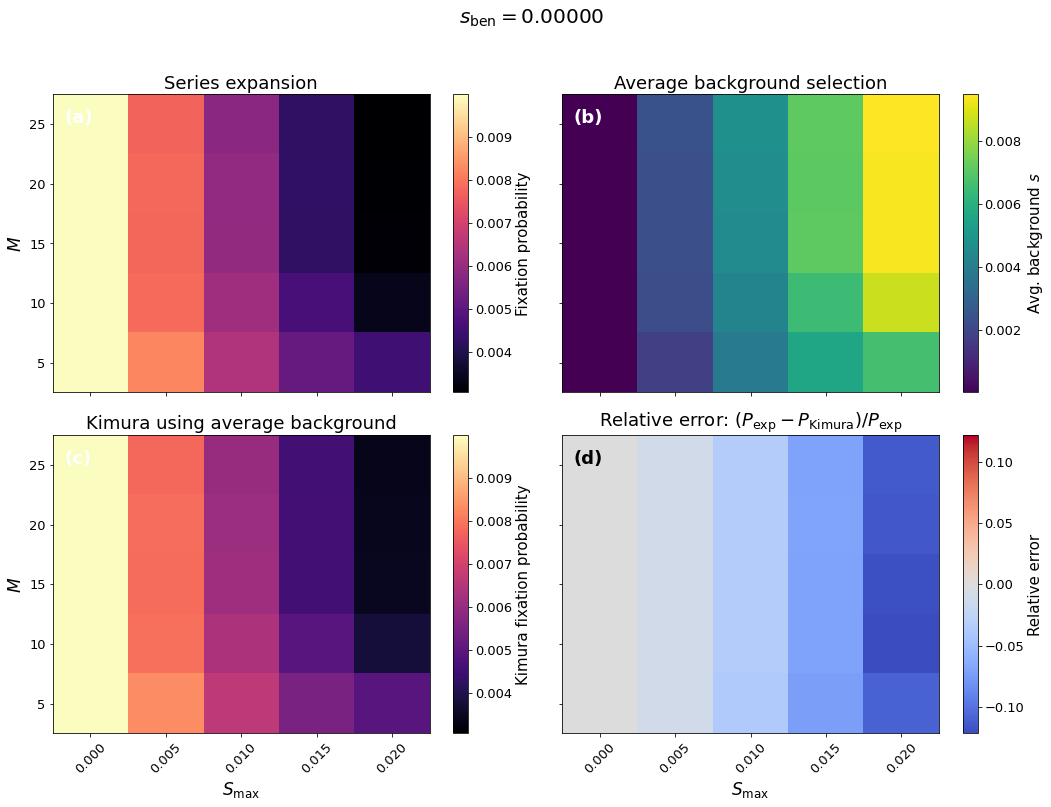


Requested SBEN = 0.005000; using nearest grid value SBENsets[1] = 0.005000
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_SBEN_0.00500_SMAX_2_0.02000.pdf


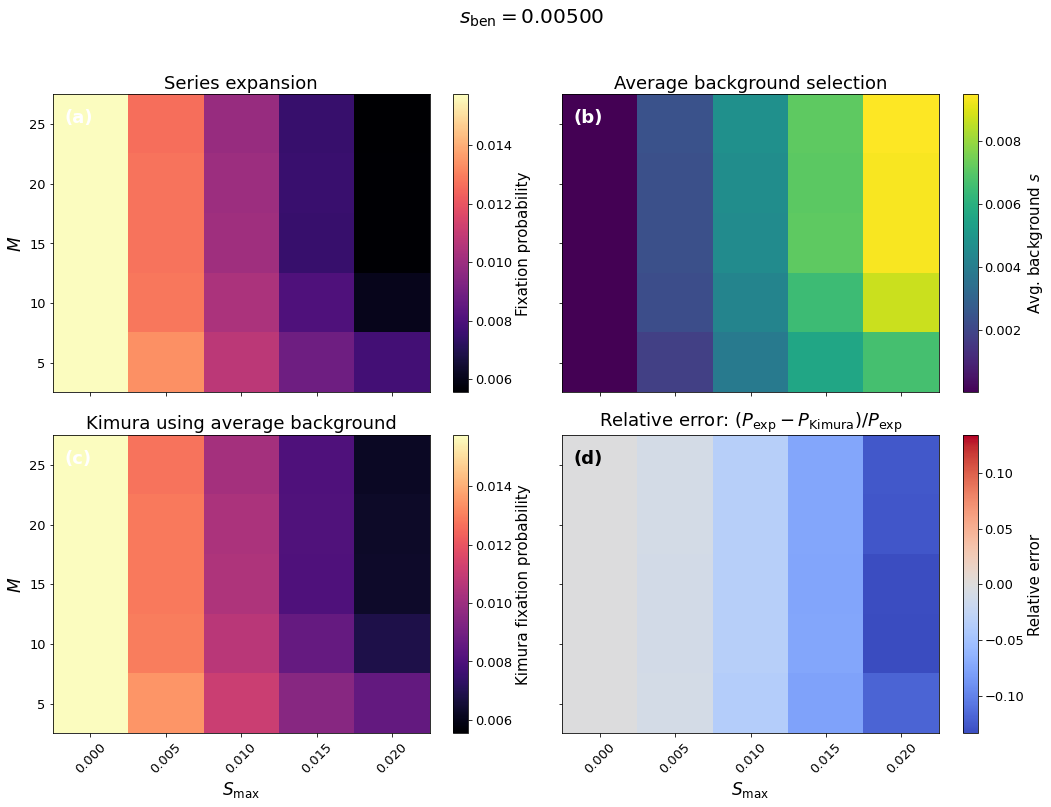


Requested SBEN = 0.010000; using nearest grid value SBENsets[2] = 0.010000
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_SBEN_0.01000_SMAX_2_0.02000.pdf


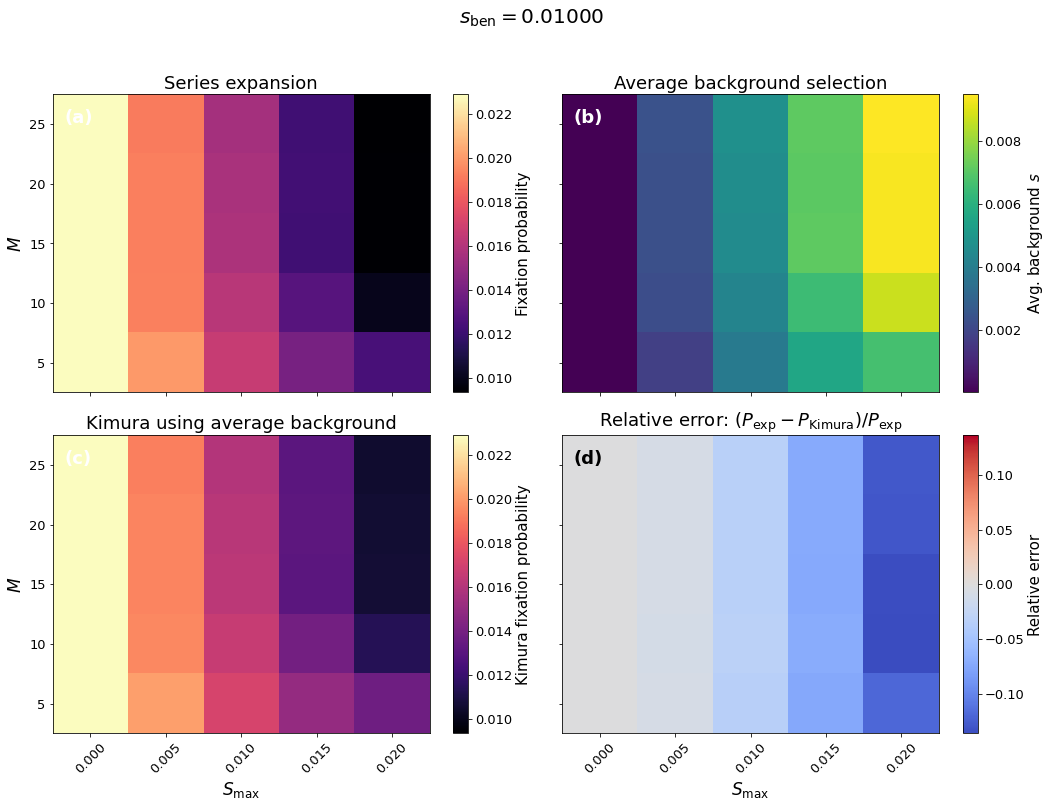


Requested SBEN = 0.015000; using nearest grid value SBENsets[3] = 0.015000
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_SBEN_0.01500_SMAX_2_0.02000.pdf


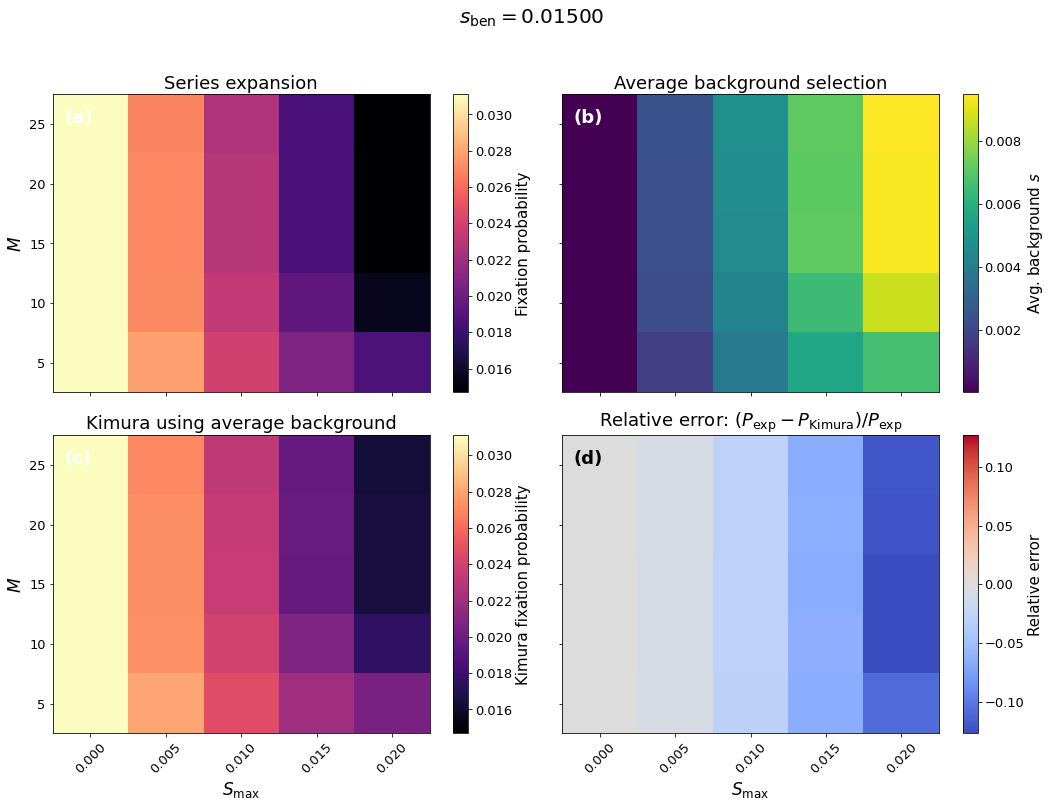


Requested SBEN = 0.020000; using nearest grid value SBENsets[4] = 0.020000
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_SBEN_0.02000_SMAX_2_0.02000.pdf


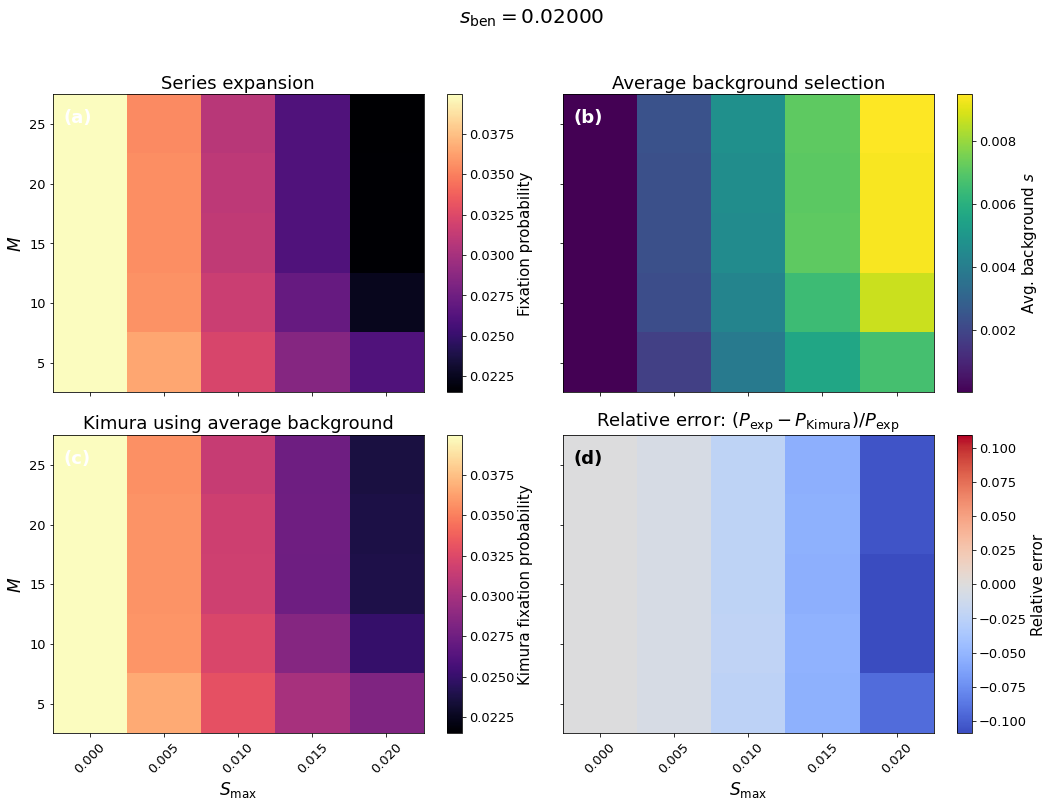

In [84]:
# ============================================================
# User choice: which SBEN values to plot
# ============================================================

#SBEN_to_plot = [0.01, 0.02]
#SBEN_to_plot = [SBENsets[0], SBENsets[-1]] # firs, last
SBEN_to_plot = SBENsets # plot all

results = {}

for sben_requested in SBEN_to_plot:
    b = nearest_sben_index(sben_requested, SBENsets)
    sben_actual = SBENsets[b]

    print(
        f"\nRequested SBEN = {sben_requested:.6f}; "
        f"using nearest grid value SBENsets[{b}] = {sben_actual:.6f}"
    )

    results[sben_actual] = plot_sben_heatmaps(b, save=True)




Requested SBEN = 0.000000; using nearest grid value SBENsets[0] = 0.000000

Requested SBEN = 0.006000; using nearest grid value SBENsets[2] = 0.006000

Requested SBEN = 0.012000; using nearest grid value SBENsets[4] = 0.012000
Saved: data_fix_prob/Single_benef_mut_panels_A_D_grid_K3_SMAX_2_0.01000.pdf


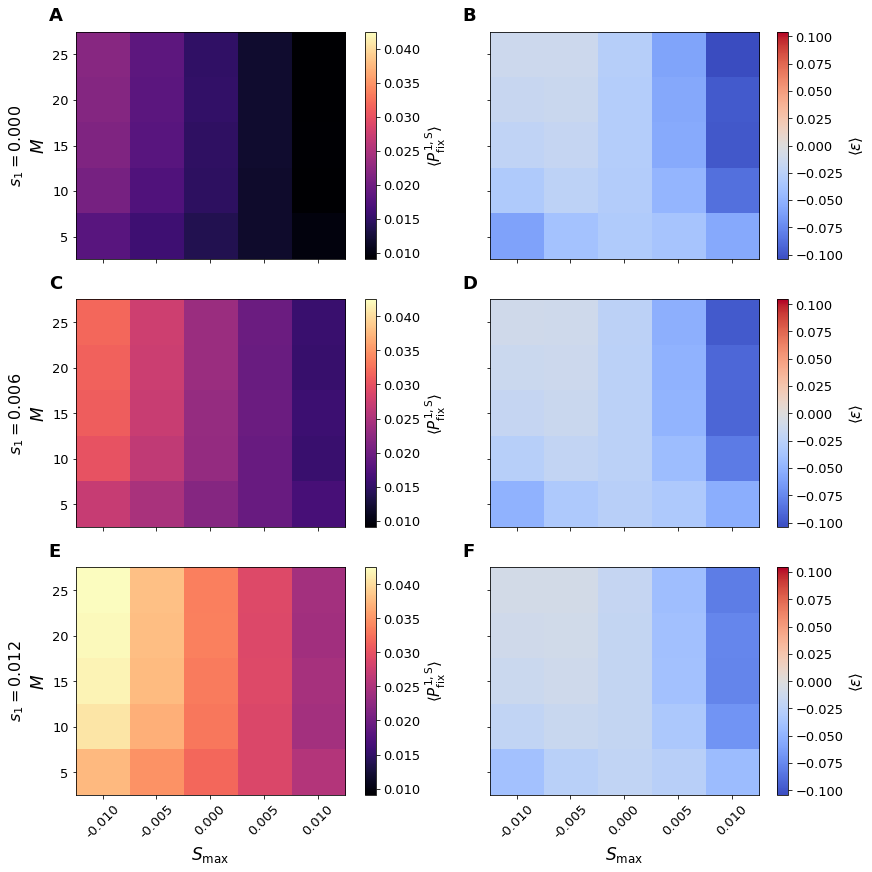

In [200]:
if BENmut == True:
    sben_requested_array = [0.00, 0.01, 0.02] # beneficial
else:
    sben_requested_array = [0.00, 0.006, 0.012] # deleterious
#sben_requested_array=SBENsets

results_AD = plot_sben_panels_a_d_grid(
    sben_requested_array=sben_requested_array,
    save=True
)

#debug
#print(results_AD[sben_requested_array[0]]["heatmap_fix"],"\n") # panels A, C, E, ...
#print(results_AD[sben_requested_array[0]]["heatmap_relerr"]) # panels B, D, F, ...


In [197]:
###########################
# Plot SBEN scan results, part 2
###########################

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import os

# ============================================================
# 0. Parameters matching the SBEN-scan run
# ============================================================

########################## High-res scan over M and SMAX for a few values of SBEN

"""
N = 100
D = 50

N_M = 20
N_SMIN = 1
N_SMAX = 20
N_SBEN = 2

Min = 5
Max = 50
Msets = np.linspace(Min, Max, num=N_M, dtype=int)

SMIN_1 = 0.0
SMIN_2 = 0.0

SMAX_1 = 0.0
SMAX_2 = 0.02
SMAXsets = np.linspace(SMAX_1, SMAX_2, num=N_SMAX)

SBEN_1 = 0.01
SBEN_2 = 0.02
SBENsets = np.linspace(SBEN_1, SBEN_2, num=N_SBEN)
"""

########################## Medium-res scan over M, SMAX and SBEN

BENmut = False # BEN or DEL scenarios

N = 100 # total number of individuals in the population
D = 100 # total number of randomly sampled selection coefficient sets

N_M = 5 # total number of M values
N_SMIN = 1 # total number of SMIN sets
N_SMAX = 5 # total number of SMAX sets
N_SBEN = 5

Min = 5 # min M
Max = 25 # max M
Msets = np.linspace(Min, Max, num=N_M, dtype=int) # array of M

if BENmut == True:
    SMIN_1 = 0.0 # beneficial interfering mutations
    SMIN_2 = 0.0
else:
    SMIN_1 = -0.01 # deleterious interfering mutations
    SMIN_2 = -0.01

if BENmut == True:
    SMAX_1 = 0.0 # beneficial interfering mutations
    SMAX_2 = 0.02
else:
    SMAX_1 = -0.01 # deleterious interfering mutations
    SMAX_2 = 0.01
#################
SMAXsets = np.linspace(SMAX_1, SMAX_2, num=N_SMAX) # array of SMAX

# Beneficial mutation selection coefficient scan
SBEN_1 = 0.0
if BENmut == True:
    SBEN_2 = 0.02 # beneficial interfering mutations
else:
    SBEN_2 = 0.012 # deleterious interfering mutations
#################
SBENsets = np.linspace(SBEN_1, SBEN_2, num=N_SBEN)

#########################################################################


folder = "data_fix_prob"

# ============================================================
# 1. Load SBEN-scan data
# ============================================================

f1 = (
    f"fprobs_expan_rsets.SBEN_{SBEN_1}-{SBEN_2}_NSBEN{N_SBEN}_"
    f"N{N}_M_{Min}-{Max}_SMIN_{SMIN_1}-{SMIN_2}_"
    f"SMAX_{SMAX_1}-{SMAX_2}_D{D}.npy"
)

f2 = (
    f"sel_coeff_expan_rsets.SBEN_{SBEN_1}-{SBEN_2}_NSBEN{N_SBEN}_"
    f"N{N}_M_{Min}-{Max}_SMIN_{SMIN_1}-{SMIN_2}_"
    f"SMAX_{SMAX_1}-{SMAX_2}_D{D}.npy"
)

fix_probs = np.load(os.path.join(folder, f1))
sel_coeffs_g = np.load(os.path.join(folder, f2))

print("Loaded file:", f1)
print("Loaded file:", f2, "\n")

print("fix_probs.shape    =", fix_probs.shape)
print("sel_coeffs_g.shape =", sel_coeffs_g.shape)

assert fix_probs.shape == (N_SBEN, N_M, N_SMIN, N_SMAX, D)
assert sel_coeffs_g.shape[1:] == (N_SBEN, N_M, N_SMIN, N_SMAX, D)

# ============================================================
# 2. Helper functions
# ============================================================

# Note that <s_{bkgr}> must be freq_weighted for non-uniform distributions of interfering mutations!
def kimura_fixation_probability(N, s, x, atol=1e-14):
    """
    Kimura fixation probability:
        P_fix = (1 - exp(-2 N s x)) / (1 - exp(-2 N s))

    Uses expm1 for numerical stability and returns x in the neutral limit s -> 0.
    Avoids runtime warnings by not dividing where s is effectively zero.
    """
    s = np.asarray(s, dtype=float)
    x = np.asarray(x, dtype=float)

    # Broadcast s and x to a common shape
    s, x = np.broadcast_arrays(s, x)

    neutral = np.isclose(s, 0.0, atol=atol)

    numerator = -np.expm1(-2.0 * N * s * x)
    denominator = -np.expm1(-2.0 * N * s)

    # Start with the neutral-limit value
    out = np.array(x, dtype=float, copy=True)

    # Only divide for non-neutral entries
    np.divide(
        numerator,
        denominator,
        out=out,
        where=~neutral
    )

    # Return scalar if inputs were scalar-like
    if out.ndim == 0:
        return out.item()

    return out


def nearest_M_index(M_value, Msets):
    """
    Return index of nearest M value in Msets.
    """
    return int(np.argmin(np.abs(Msets - M_value)))

# ============================================================
# 3. Plot function for one chosen M
# ============================================================

def plot_M_heatmaps(j, save=True):
    """
    Make the 2x2 heatmap plot for fixed M index j.

    Axes:
        x-axis = SMAX
        y-axis = SBEN

    Panels:
        (a) Series expansion fixation probability
        (b) Average background selection coefficient
        (c) Kimura fixation probability
        (d) Relative error:
            (Series expansion - Kimura) / Series expansion

    Returns a dictionary storing the plotted matrices.
    """

    M = Msets[j]

    # ------------------------------------------------------------
    # (a) Series-expansion fixation probability
    #
    # fix_probs[:, j, 0, :, :] shape = (N_SBEN, N_SMAX, D)
    # average over D -> shape = (N_SBEN, N_SMAX)
    # ------------------------------------------------------------
    heatmap_fix = np.mean(fix_probs[:, j, 0, :, :], axis=2)

    # ------------------------------------------------------------
    # (b) Average background selection coefficient
    #
    # For fixed M, heatmap axes are:
    #     rows    = SBEN
    #     columns = SMAX
    # ------------------------------------------------------------
    heatmap_bg = np.full((N_SBEN, N_SMAX), np.nan)

    # Not averaged over D
    kimura_ave_sel = np.full((N_SBEN, N_SMAX, D), np.nan)

    for b in range(N_SBEN):
        SBEN = SBENsets[b]

        # Safety checks
        assert np.allclose(sel_coeffs_g[0, b, j, 0, :, :], SBEN), \
            f"First entry is not SBEN for b={b}, j={j}, M={M}"

        assert np.allclose(sel_coeffs_g[M - 1, b, j, 0, :, :], 0.0), \
            f"Last retained entry is not 0.0 for b={b}, j={j}, M={M}"

        if M < sel_coeffs_g.shape[0]:
            assert np.all(sel_coeffs_g[M:, b, j, 0, :, :] == -1.0), \
                f"Padding after valid entries is not all -1 for b={b}, j={j}, M={M}"

        # Remove index 0 = SBEN, keep indices 1,...,M-1.
        # This includes the final 0.0 and excludes -1 padding.
        #
        # Shape: (M-1, N_SMAX, D)
        bg_entries = sel_coeffs_g[1:M, b, j, 0, :, :]

        # Average over background entries, but not over D.
        # Shape: (N_SMAX, D)
        #kimura_ave_sel[b, :, :] = np.mean(bg_entries, axis=0)
        kimura_ave_sel[b, :, :] = (1 - 1/N) * np.mean(bg_entries, axis=0) # each bkgr mut has (1 - 1/N)/(M - 1) freq.

        # Average over D for panel (b).
        # Shape: (N_SMAX,)
        heatmap_bg[b, :] = np.mean(kimura_ave_sel[b, :, :], axis=1)

    # ------------------------------------------------------------
    # (c) Kimura approximation
    # ------------------------------------------------------------
    s_cur = SBENsets[:, None, None] - kimura_ave_sel
    #x_cur = 1.0 / M  # uniform freqs
    x_cur = 1.0 / N  # single initial mutant

    kimura_pfix = kimura_fixation_probability(
        N=N,
        s=s_cur,
        x=x_cur
    )
    
    ### HACK for the neutral example ONLY ###
    #kimura_pfix = kimura_fixation_probability(
    #    N=N,
    #    s=0.0,
    #    x=x_cur
    #)
    
    # Average over D
    kimura_pfix_ave = np.mean(kimura_pfix, axis=2)

    # ------------------------------------------------------------
    # (d) Relative error
    # ------------------------------------------------------------
    with np.errstate(divide="ignore", invalid="ignore"):
        heatmap_relerr = (heatmap_fix - kimura_pfix_ave) / heatmap_fix

    heatmap_relerr = np.where(np.isfinite(heatmap_relerr), heatmap_relerr, np.nan)
    
    # Average of the errors, NOT errors of the averages:
    # fix_probs[:, j, 0, :, :] shape = (N_SBEN, N_SMAX, D)
    with np.errstate(divide="ignore", invalid="ignore"):
        heatmap_relerr_all = (fix_probs[:, j, 0, :, :] - kimura_pfix) / fix_probs[:, j, 0, :, :] # (N_SBEN, N_SMAX, D)
    
    heatmap_relerr_all = np.where(np.isfinite(heatmap_relerr_all), heatmap_relerr_all, np.nan)
    heatmap_relerr = np.mean(heatmap_relerr_all, axis=2) # average over D relative errors
    
    # ============================================================
    # 4. Plot 2x2 heatmap matrix
    # ============================================================
    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 11),
        sharex=True,
        sharey=True
    )

    label_fs = 17
    title_fs = 18
    tick_fs = 13
    cbar_fs = 15
    panel_fs = 18

    xticks = np.arange(N_SMAX)
    xticklabels = [f"{x:.4f}" for x in SMAXsets]

    yticks = np.arange(N_SBEN)
    yticklabels = [f"{s:.4f}" for s in SBENsets]

    # Same colormap and same normalization for panels (a) and (c)
    fix_cmap = "magma"
    pfix_min = np.nanmin([np.nanmin(heatmap_fix), np.nanmin(kimura_pfix_ave)])
    pfix_max = np.nanmax([np.nanmax(heatmap_fix), np.nanmax(kimura_pfix_ave)])

    # Symmetric color scale for relative error
    relerr_abs = np.nanmax(np.abs(heatmap_relerr))
    if not np.isfinite(relerr_abs) or relerr_abs == 0:
        relerr_norm = None
    else:
        relerr_norm = TwoSlopeNorm(
            vmin=-relerr_abs,
            vcenter=0.0,
            vmax=relerr_abs
        )

    # -----------------------------
    # Panel (a): series expansion
    # -----------------------------
    ax = axes[0, 0]
    im = ax.imshow(
        heatmap_fix,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=fix_cmap,
        vmin=pfix_min,
        vmax=pfix_max
    )

    ax.set_title("Series expansion", fontsize=title_fs)
    ax.set_ylabel(r"$s_{\rm ben}$", fontsize=label_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Fixation probability", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(a)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="white"
    )

    # -----------------------------
    # Panel (b): average background selection
    # -----------------------------
    ax = axes[0, 1]
    im = ax.imshow(
        heatmap_bg,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap="viridis"
    )

    ax.set_title("Average background selection", fontsize=title_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r"Avg. background $s$", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(b)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="white"
    )

    # -----------------------------
    # Panel (c): Kimura approximation
    # -----------------------------
    ax = axes[1, 0]
    im = ax.imshow(
        kimura_pfix_ave,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=fix_cmap,
        vmin=pfix_min,
        vmax=pfix_max
    )

    ax.set_title("Kimura using average background", fontsize=title_fs)
    ax.set_xlabel(r"$S_{\max}$", fontsize=label_fs)
    ax.set_ylabel(r"$s_{\rm ben}$", fontsize=label_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Kimura fixation probability", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(c)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="white"
    )

    # -----------------------------
    # Panel (d): relative error
    # -----------------------------
    ax = axes[1, 1]
    im = ax.imshow(
        heatmap_relerr,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        norm=relerr_norm
    )

    ax.set_title(
        r"Relative error: $(P_{\rm exp}-P_{\rm Kimura})/P_{\rm exp}$",
        fontsize=title_fs
    )
    ax.set_xlabel(r"$S_{\max}$", fontsize=label_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Relative error", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(d)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="black"
    )

    # -----------------------------
    # Shared tick formatting
    # -----------------------------
    for ax in axes.flat:
        ax.set_xticks(xticks)
        ax.set_xticklabels(xticklabels, rotation=45, fontsize=tick_fs)
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticklabels, fontsize=tick_fs)

    fig.suptitle(rf"$M = {M}$", fontsize=20, y=1.02)

    plt.tight_layout()

    if save:
        fout = f"Single_benef_mut_fixation_prob_2x2_M_{M}.pdf"
        fout = os.path.join(folder, fout)
        plt.savefig(fout, bbox_inches="tight")
        print("Saved:", fout)

    plt.show()

    return {
        "M": M,
        "M_index": j,
        "heatmap_fix": heatmap_fix,
        "heatmap_bg": heatmap_bg,
        "kimura_ave_sel": kimura_ave_sel,
        "kimura_pfix_ave": kimura_pfix_ave,
        "heatmap_relerr": heatmap_relerr,
    }

def compute_M_panels_a_d(j):
    """
    Compute only panel (a) and panel (d) quantities for M index j.

    Returns:
        heatmap_fix:
            average series-expansion fixation probability,
            shape (N_SBEN, N_SMAX)

        heatmap_relerr:
            average over D of per-realization relative errors,
            shape (N_SBEN, N_SMAX)

    Uses the same data structures and conventions as plot_M_heatmaps().
    """

    M = Msets[j]

    # ------------------------------------------------------------
    # Panel (a): series-expansion fixation probability
    #
    # fix_probs[:, j, 0, :, :] shape = (N_SBEN, N_SMAX, D)
    # ------------------------------------------------------------
    heatmap_fix = np.mean(fix_probs[:, j, 0, :, :], axis=2)

    # ------------------------------------------------------------
    # Recompute Kimura quantity, as in plot_M_heatmaps()
    # ------------------------------------------------------------
    kimura_ave_sel = np.full((N_SBEN, N_SMAX, D), np.nan)

    for b in range(N_SBEN):
        SBEN = SBENsets[b]

        assert np.allclose(sel_coeffs_g[0, b, j, 0, :, :], SBEN), \
            f"First entry is not SBEN for b={b}, j={j}, M={M}"

        assert np.allclose(sel_coeffs_g[M - 1, b, j, 0, :, :], 0.0), \
            f"Last retained entry is not 0.0 for b={b}, j={j}, M={M}"

        if M < sel_coeffs_g.shape[0]:
            assert np.all(sel_coeffs_g[M:, b, j, 0, :, :] == -1.0), \
                f"Padding after valid entries is not all -1 for b={b}, j={j}, M={M}"

        # Remove index 0 = SBEN, keep indices 1,...,M-1.
        # This includes the final 0.0 and excludes padding.
        bg_entries = sel_coeffs_g[1:M, b, j, 0, :, :]   # shape: (M-1, N_SMAX, D)

        # Same weighting as in your current plot_M_heatmaps()
        #kimura_ave_sel[b, :, :] = (1.0 - 1.0 / N) * np.mean(bg_entries, axis=0)
        kimura_ave_sel[b, :, :] = np.mean(bg_entries, axis=0) # use RELATIVE freqs

    # ------------------------------------------------------------
    # Kimura approximation
    # ------------------------------------------------------------
    s_cur = SBENsets[:, None, None] - kimura_ave_sel    # shape: (N_SBEN, N_SMAX, D)
    x_cur = 1.0 / N                                     # single initial mutant

    kimura_pfix = kimura_fixation_probability(
        N=N,
        s=s_cur,
        x=x_cur
    )

    # ------------------------------------------------------------
    # Panel (d): average of per-realization relative errors
    # ------------------------------------------------------------
    with np.errstate(divide="ignore", invalid="ignore"):
        heatmap_relerr_all = (
            fix_probs[:, j, 0, :, :] - kimura_pfix
        ) / fix_probs[:, j, 0, :, :]                    # shape: (N_SBEN, N_SMAX, D)

    heatmap_relerr_all = np.where(
        np.isfinite(heatmap_relerr_all),
        heatmap_relerr_all,
        np.nan
    )

    heatmap_relerr = np.mean(heatmap_relerr_all, axis=2)

    return {
        "M": M,
        "M_index": j,
        "heatmap_fix": heatmap_fix,
        "kimura_pfix": kimura_pfix,
        "heatmap_relerr": heatmap_relerr,
    }


def plot_M_panels_a_d_grid(
    M_requested_array,
    save=True,
    fout=None,
    figsize_per_row=(12, 4.0),
    pfix_cmap="magma",
    relerr_cmap="coolwarm"
):
    """
    For a user-chosen list/array of M values, make a K x 2 panel figure.

    Columns:
        left  = panel (A), (C), (E), ... : average series-expansion fixation probability
        right = panel (B), (D), (F), ... : average relative error

    Rows:
        different user-chosen M values

    Heatmap axes:
        x-axis = S_max
        y-axis = s_1 = s_ben

    Returns:
        results dictionary keyed by actual M grid value.
    """

    M_requested_array = np.asarray(M_requested_array, dtype=int)
    K = len(M_requested_array)

    if K == 0:
        raise ValueError("M_requested_array must contain at least one value.")

    # ------------------------------------------------------------
    # First compute all heatmaps and store them
    # ------------------------------------------------------------
    results = {}

    for M_requested in M_requested_array:
        j = nearest_M_index(M_requested, Msets)
        M_actual = Msets[j]

        print(
            f"\nRequested M = {M_requested}; "
            f"using nearest grid value Msets[{j}] = {M_actual}"
        )

        results[M_actual] = compute_M_panels_a_d(j)

    # ------------------------------------------------------------
    # Global color normalization across all selected M values
    # ------------------------------------------------------------
    all_fix = np.concatenate([
        results[M]["heatmap_fix"].ravel()
        for M in results
    ])

    all_rel = np.concatenate([
        results[M]["heatmap_relerr"].ravel()
        for M in results
    ])

    pfix_min = np.nanmin(all_fix)
    pfix_max = np.nanmax(all_fix)

    relerr_abs = np.nanmax(np.abs(all_rel))
    if not np.isfinite(relerr_abs) or relerr_abs == 0.0:
        relerr_norm = None
    else:
        relerr_norm = TwoSlopeNorm(
            vmin=-relerr_abs,
            vcenter=0.0,
            vmax=relerr_abs
        )

    # ------------------------------------------------------------
    # Figure setup
    # ------------------------------------------------------------
    fig_width = figsize_per_row[0]
    fig_height = figsize_per_row[1] * K

    fig, axes = plt.subplots(
        K,
        2,
        figsize=(fig_width, fig_height),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True
    )

    label_fs = 17
    title_fs = 18
    tick_fs = 13
    cbar_fs = 13
    panel_fs = 18
    row_fs = 16

    xticks = np.arange(N_SMAX)
    xticklabels = [f"{x:.3f}" for x in SMAXsets]

    yticks = np.arange(N_SBEN)
    yticklabels = [f"{s:.3f}" for s in SBENsets]

    # Uppercase labels: A, B, C, ...
    panel_labels = [
        f"{chr(ord('A') + n)}"
        for n in range(2 * K)
    ]

    # ------------------------------------------------------------
    # Plot rows
    # ------------------------------------------------------------
    for row, M_actual in enumerate(results.keys()):

        heatmap_fix = results[M_actual]["heatmap_fix"]
        heatmap_relerr = results[M_actual]["heatmap_relerr"]

        # -----------------------------
        # Left column: panel (A), (C), (E), ...
        # -----------------------------
        ax = axes[row, 0]

        im_fix = ax.imshow(
            heatmap_fix,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            cmap=pfix_cmap,
            vmin=pfix_min,
            vmax=pfix_max
        )

        # if row == 0:
        #     ax.set_title("Series expansion", fontsize=title_fs)

        ax.set_ylabel(r"$s_1$", fontsize=label_fs)

        # Row annotation with actual M value
        ax.text(
            -0.30, 0.50,
            rf"$M={M_actual}$",
            transform=ax.transAxes,
            fontsize=row_fs,
            rotation=90,
            va="center",
            ha="center",
            clip_on=False
        )

        # Uppercase boldface panel label, outside upper-left
        ax.text(
            -0.10, 1.03,
            panel_labels[2 * row],
            transform=ax.transAxes,
            fontsize=panel_fs,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False
        )

        # Separate colorbar for this panel
        cbar_fix = fig.colorbar(
            im_fix,
            ax=ax,
            fraction=0.046,
            pad=0.04
        )
        cbar_fix.set_label(r"$\langle P_\mathrm{fix}^{1,\mathrm{S}} \rangle$", fontsize=cbar_fs+2)
        cbar_fix.ax.tick_params(labelsize=tick_fs)

        # -----------------------------
        # Right column: panel (B), (D), (F), ...
        # -----------------------------
        ax = axes[row, 1]

        im_rel = ax.imshow(
            heatmap_relerr,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            cmap=relerr_cmap,
            norm=relerr_norm
        )

        # if row == 0:
        #     ax.set_title(r"Relative error", fontsize=title_fs)

        # Uppercase boldface panel label, outside upper-left
        ax.text(
            -0.10, 1.03,
            panel_labels[2 * row + 1],
            transform=ax.transAxes,
            fontsize=panel_fs,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False
        )

        # Separate colorbar for this panel
        cbar_rel = fig.colorbar(
            im_rel,
            ax=ax,
            fraction=0.046,
            pad=0.04
        )
        cbar_rel.set_label(
            r"$\langle \varepsilon \rangle$",
            fontsize=cbar_fs+2
        )
        cbar_rel.ax.tick_params(labelsize=tick_fs)

    # ------------------------------------------------------------
    # Shared ticks and labels
    # ------------------------------------------------------------
    for row in range(K):
        for col in range(2):
            ax = axes[row, col]

            ax.set_xticks(xticks)
            ax.set_xticklabels(
                xticklabels,
                rotation=45,
                fontsize=tick_fs
            )

            ax.set_yticks(yticks)
            ax.set_yticklabels(
                yticklabels,
                fontsize=tick_fs
            )

    for col in range(2):
        axes[-1, col].set_xlabel(r"$S_{\max}$", fontsize=label_fs)

    if save:
        if fout is None:
            fout = (
                f"Single_benef_mut_panels_A_D_grid_"
                f"M_K{K}_SMAX_2_{SMAX_2:.5f}.pdf"
            )
            fout = os.path.join(folder, fout)

        plt.savefig(fout, bbox_inches="tight")
        print("Saved:", fout)

    plt.show()

    return results


Loaded file: fprobs_expan_rsets.SBEN_0.0-0.012_NSBEN5_N100_M_5-25_SMIN_-0.01--0.01_SMAX_-0.01-0.01_D100.npy
Loaded file: sel_coeff_expan_rsets.SBEN_0.0-0.012_NSBEN5_N100_M_5-25_SMIN_-0.01--0.01_SMAX_-0.01-0.01_D100.npy 

fix_probs.shape    = (5, 5, 1, 5, 100)
sel_coeffs_g.shape = (25, 5, 5, 1, 5, 100)



Requested M = 5; using nearest grid value Msets[0] = 5
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_M_5.pdf


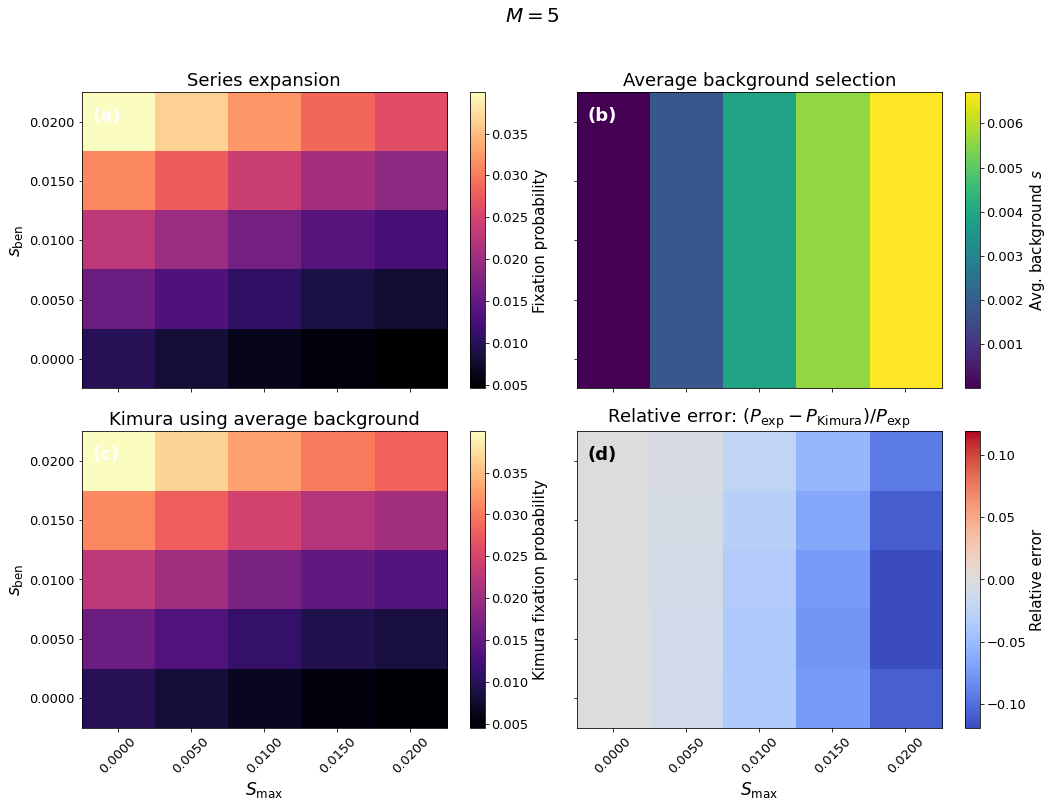


Requested M = 10; using nearest grid value Msets[1] = 10
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_M_10.pdf


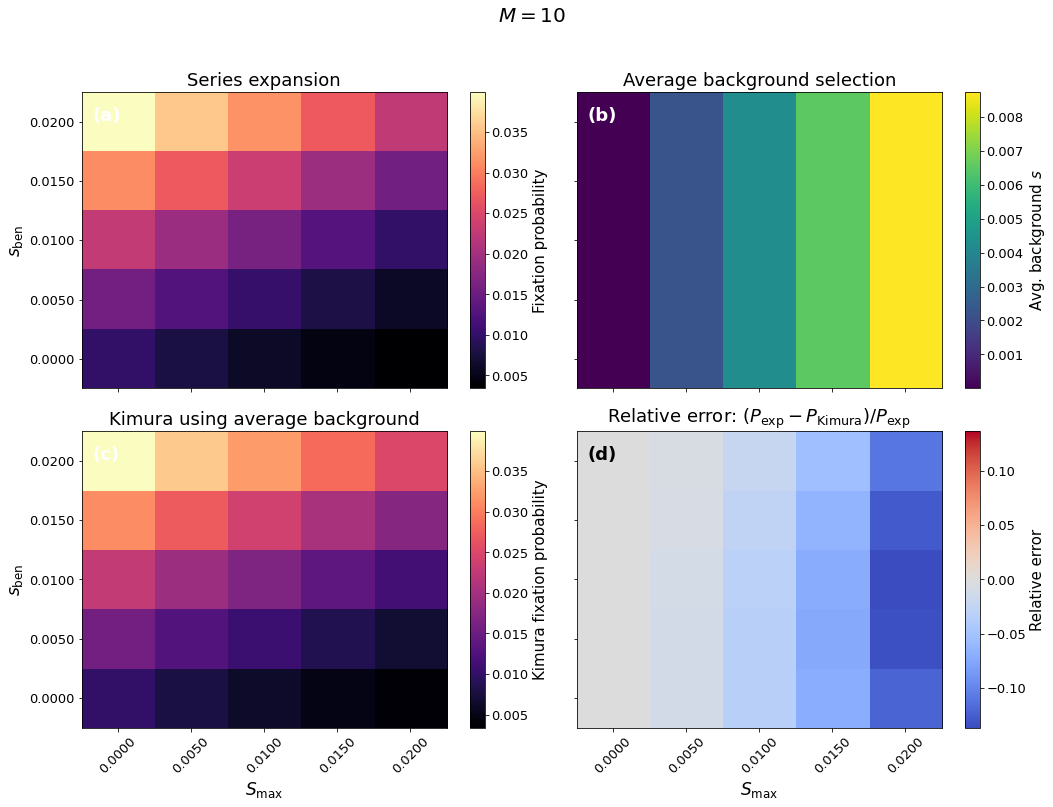


Requested M = 15; using nearest grid value Msets[2] = 15
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_M_15.pdf


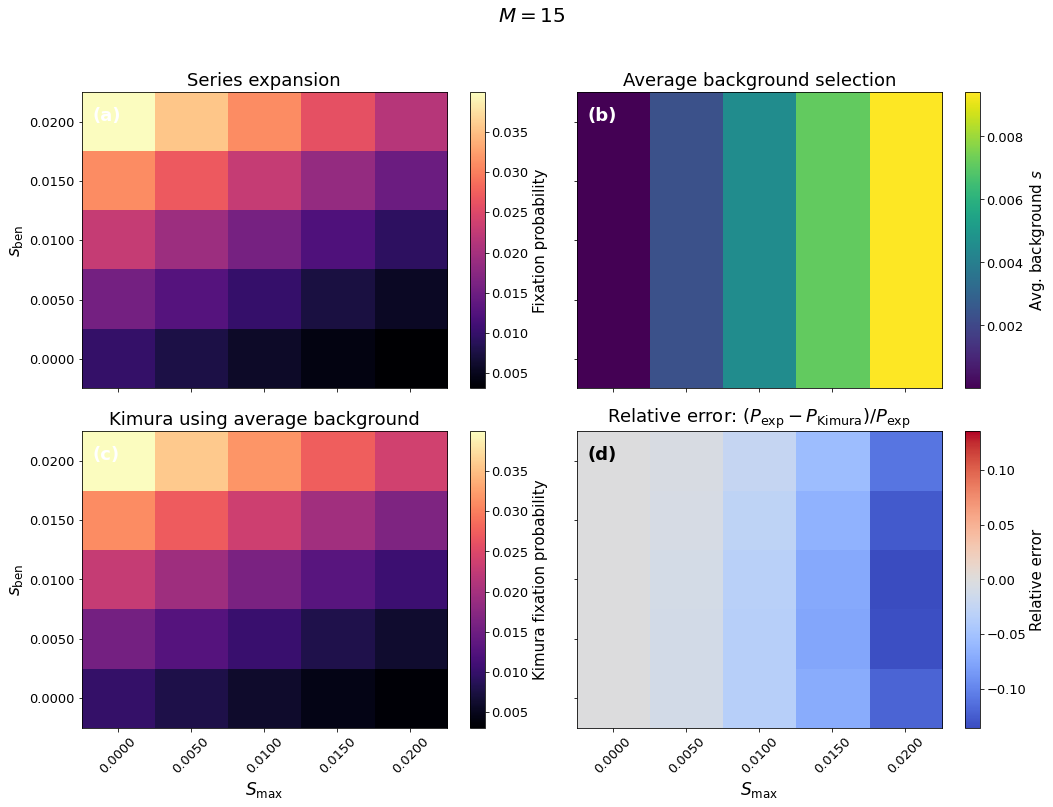


Requested M = 20; using nearest grid value Msets[3] = 20
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_M_20.pdf


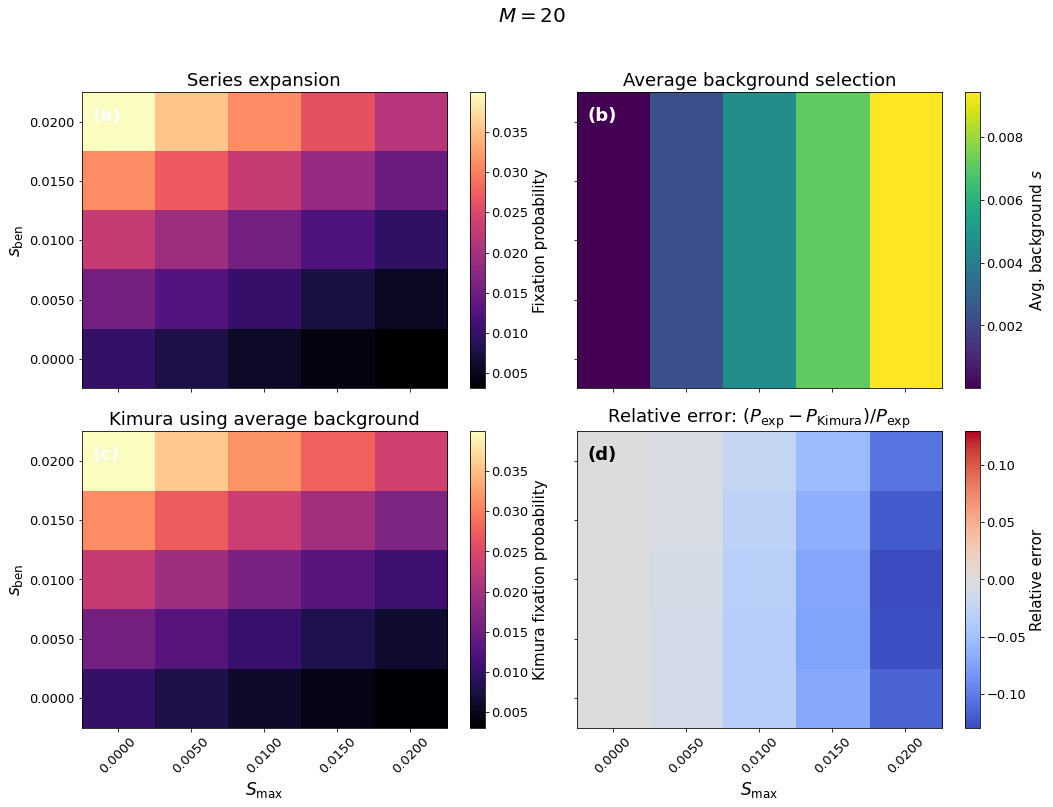


Requested M = 25; using nearest grid value Msets[4] = 25
Saved: data_fix_prob/Single_benef_mut_fixation_prob_2x2_M_25.pdf


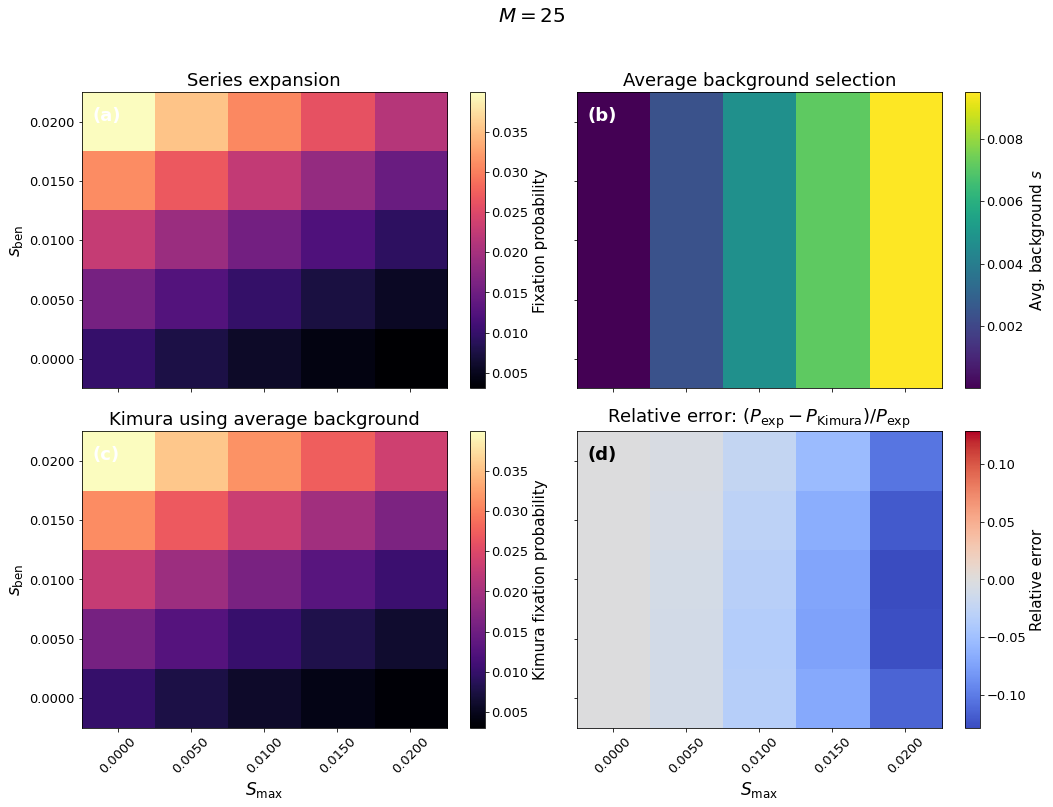

In [53]:
# ============================================================
# User choice: which M values to plot
# ============================================================

#M_to_plot = [5, 15, 25]
# M_to_plot = [Msets[0], Msets[-1]]
M_to_plot = Msets # plot all

# ============================================================
# 5. Make plots and store matrices in results dictionary
# ============================================================

results = {}

for M_requested in M_to_plot:
    j = nearest_M_index(M_requested, Msets)
    M_actual = Msets[j]

    print(
        f"\nRequested M = {M_requested}; "
        f"using nearest grid value Msets[{j}] = {M_actual}"
    )

    results[M_actual] = plot_M_heatmaps(j, save=True)




Requested M = 5; using nearest grid value Msets[0] = 5

Requested M = 15; using nearest grid value Msets[2] = 15

Requested M = 25; using nearest grid value Msets[4] = 25
Saved: data_fix_prob/Single_benef_mut_panels_A_D_grid_M_K3_SMAX_2_0.01000.pdf


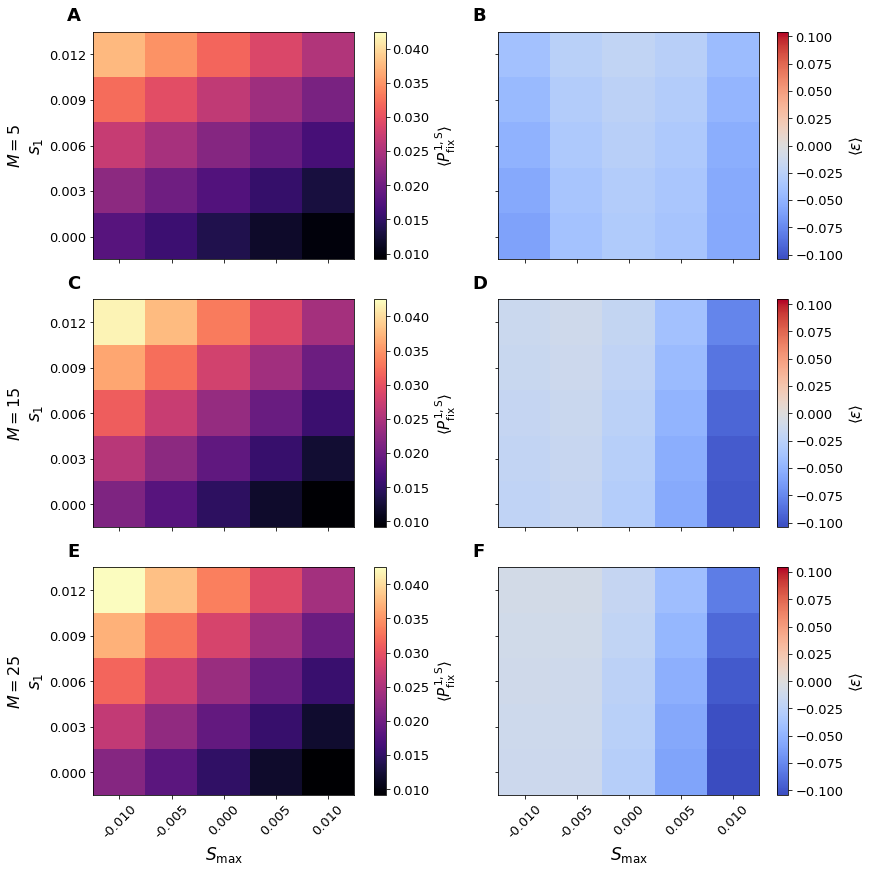

In [198]:
M_to_plot = [5, 15, 25] # beneficial OR deleterious
#M_to_plot = Msets # plot all

results_M_AD = plot_M_panels_a_d_grid(
    M_requested_array=M_to_plot,
    save=True
)

#debug
#print(results_M_AD[5]["heatmap_fix"],"\n")  # panel A if M=5 is the first requested row
#print("=================")
#print(results_M_AD[15]["heatmap_fix"],"\n")  # panel A if M=5 is the first requested row
#print(results_M_AD[5]["heatmap_relerr"])    # panel B if M=5 is the first requested row


In [184]:
#########################
# Plot q-scan results
#########################

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from copy import copy
import os

# ============================================================
# 0. Load saved data
# ============================================================

folder = "data_fix_prob"

in_file = os.path.join(
    folder,
    "interference_model_scan_"
    "N100_M_3-15_"
    "SB_0.0-0.02_NSB11_"
    #"q_0.0010-0.7990_NQ11_"
    #"q_0.0010-0.8000_NQ11_"
    "q_0.0000-0.8000_NQ9_"
    "Sh_0.0-0.02_NSh11.npz"
)

data = np.load(in_file)

fix_probs_expansion = data["fix_probs_expansion"]
fix_probs_kimura    = data["fix_probs_kimura"]

Msets  = data["Msets"]
SBsets = data["SBsets"]
qsets  = data["qsets"]
Shsets = data["Shsets"]

# Optional validity mask, if saved
if "valid_expansion" in data.files:
    valid_expansion = data["valid_expansion"].astype(bool)
else:
    valid_expansion = np.isfinite(fix_probs_expansion)

N_M  = len(Msets)
N_SB = len(SBsets)
N_Q  = len(qsets)
N_Sh = len(Shsets)

print("Loaded:", in_file)
print("fix_probs_expansion.shape =", fix_probs_expansion.shape)
print("fix_probs_kimura.shape    =", fix_probs_kimura.shape)
print("valid_expansion.shape     =", valid_expansion.shape)

assert fix_probs_expansion.shape == (N_M, N_SB, N_Q, N_Sh)
assert fix_probs_kimura.shape    == (N_M, N_SB, N_Q, N_Sh)
assert valid_expansion.shape     == (N_M, N_SB, N_Q, N_Sh)

# ============================================================
# 1. Helper functions
# ============================================================

def nearest_index(value, grid):
    return int(np.argmin(np.abs(grid - value)))


def relative_error(expansion, kimura, atol=1e-15):
    """
    Compute (expansion - kimura)/expansion safely.

    Returns np.nan wherever:
      - expansion is not finite
      - kimura is not finite
      - |expansion| is too small
    """
    expansion = np.asarray(expansion, dtype=float)
    kimura = np.asarray(kimura, dtype=float)

    valid = np.isfinite(expansion) & np.isfinite(kimura) & (np.abs(expansion) > atol)

    rel = np.full(expansion.shape, np.nan, dtype=float)
    rel[valid] = (expansion[valid] - kimura[valid]) / expansion[valid]

    return rel


def make_symmetric_norm(arr):
    """
    Symmetric color normalization around zero, ignoring nans.
    """
    arr = np.asarray(arr, dtype=float)
    finite = np.isfinite(arr)

    if not np.any(finite):
        return None

    vmax = np.nanmax(np.abs(arr[finite]))
    if not np.isfinite(vmax) or vmax == 0.0:
        return None

    return TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)


def set_heatmap_ticks(ax, xvals, yvals, xlabel, ylabel,
                      tick_fs=12, label_fs=16, max_ticks=8):
    """
    Use index-based imshow ticks, but label them by physical grid values.
    """
    nx = len(xvals)
    ny = len(yvals)

    xstep = max(1, nx // max_ticks)
    ystep = max(1, ny // max_ticks)

    xticks = np.arange(0, nx, xstep)
    yticks = np.arange(0, ny, ystep)

    ax.set_xticks(xticks)
    ax.set_xticklabels(
        [f"{xvals[i]:.1f}" for i in xticks], # x-axis tick labels
        rotation=45,
        fontsize=tick_fs
    )

    ax.set_yticks(yticks)
    ax.set_yticklabels(
        [f"{yvals[i]:.3f}" for i in yticks], # y-axis tick labels
        fontsize=tick_fs
    )

    ax.set_xlabel(xlabel, fontsize=label_fs)
    ax.set_ylabel(ylabel, fontsize=label_fs)


def masked_pfix_range(expansion, kimura, valid_mask):
    """
    Compute common vmin/vmax for panels (a) and (b),
    using only the valid comparison region.
    """
    vals = []

    exp_vals = expansion[valid_mask & np.isfinite(expansion)]
    kim_vals = kimura[valid_mask & np.isfinite(kimura)]

    if exp_vals.size > 0:
        vals.append(exp_vals)
    if kim_vals.size > 0:
        vals.append(kim_vals)

    if len(vals) == 0:
        return 0.0, 1.0

    vals = np.concatenate(vals)
    return np.min(vals), np.max(vals)

# ============================================================
# 2. Plotting function that handles NaNs properly
# ============================================================

def plot_three_heatmaps(
    heatmap_exp,
    heatmap_kim,
    heatmap_rel,
    xvals,
    yvals,
    xlabel,
    ylabel,
    title,
    fout=None,
    save=True
):
    """
    Plot three heatmaps in a row:
        (a) expansion
        (b) Kimura
        (c) relative error

    heatmap arrays should have shape:
        (len(yvals), len(xvals))

    NaN handling:
      - panel (a): show only finite expansion values
      - panel (b): show Kimura only where expansion is finite
      - panel (c): show relative error only where valid
    """

    heatmap_exp = np.asarray(heatmap_exp, dtype=float)
    heatmap_kim = np.asarray(heatmap_kim, dtype=float)
    heatmap_rel = np.asarray(heatmap_rel, dtype=float)

    # Valid region for comparison is where the expansion is finite
    valid_mask = np.isfinite(heatmap_exp)

    # Masked arrays for plotting
    heatmap_exp_masked = np.ma.masked_invalid(heatmap_exp)
    heatmap_kim_masked = np.ma.masked_where(~valid_mask | ~np.isfinite(heatmap_kim), heatmap_kim)
    heatmap_rel_masked = np.ma.masked_invalid(heatmap_rel)

    # Common color range for panels (a) and (b)
    pfix_min, pfix_max = masked_pfix_range(heatmap_exp, heatmap_kim, valid_mask)

    rel_norm = make_symmetric_norm(heatmap_rel)

    # Colormaps with visible bad/masked color
    pfix_cmap = copy(plt.cm.magma)
    pfix_cmap.set_bad(color="lightgreen")
    
    rel_cmap = copy(plt.cm.coolwarm)
    rel_cmap.set_bad(color="lightgreen")

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 5.4),
        sharex=True,
        sharey=True
    )

    label_fs = 16
    title_fs = 17
    tick_fs = 12
    cbar_fs = 14
    panel_fs = 18

    # ------------------------------------------------------------
    # (a) Expansion
    # ------------------------------------------------------------
    ax = axes[0]
    im = ax.imshow(
        heatmap_exp_masked,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=pfix_cmap,
        vmin=pfix_min,
        vmax=pfix_max
    )

    ax.set_title("Series expansion", fontsize=title_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Fixation probability", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(a)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="white"
    )

    # ------------------------------------------------------------
    # (b) Kimura
    # ------------------------------------------------------------
    ax = axes[1]
    im = ax.imshow(
        heatmap_kim_masked,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=pfix_cmap,
        vmin=pfix_min,
        vmax=pfix_max
    )

    ax.set_title("Kimura", fontsize=title_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Kimura fixation probability", fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(b)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="white"
    )

    # ------------------------------------------------------------
    # (c) Relative error
    # ------------------------------------------------------------
    ax = axes[2]
    im = ax.imshow(
        heatmap_rel_masked,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=rel_cmap,
        norm=rel_norm
    )

    ax.set_title(r"Relative error", fontsize=title_fs)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r"$(P_{\rm exp}-P_{\rm Kimura})/P_{\rm exp}$",
                   fontsize=cbar_fs)
    cbar.ax.tick_params(labelsize=tick_fs)

    ax.text(
        0.03, 0.95, "(c)",
        transform=ax.transAxes,
        fontsize=panel_fs,
        fontweight="bold",
        va="top",
        ha="left",
        color="black"
    )

    # ------------------------------------------------------------
    # Shared ticks and labels
    # ------------------------------------------------------------
    for ax in axes:
        set_heatmap_ticks(
            ax,
            xvals=xvals,
            yvals=yvals,
            xlabel=xlabel,
            ylabel=ylabel,
            tick_fs=tick_fs,
            label_fs=label_fs
        )

    axes[1].set_ylabel("")
    axes[2].set_ylabel("")

    fig.suptitle(title, fontsize=19, y=1.02)

    plt.tight_layout()

    if save and fout is not None:
        plt.savefig(fout, bbox_inches="tight")
        print("Saved:", fout)

    plt.show()

# ============================================================
# 3. Fixed (M, S_h): heatmaps over (S_B, q)
# ============================================================

def plot_fixed_M_Sh_over_SB_q(M_requested, Sh_requested, save=True):
    """
    For chosen M and S_h, plot heatmaps over S_B and q.

    Axes:
        x-axis = q
        y-axis = S_B
    """

    j = nearest_index(M_requested, Msets)
    iSh = nearest_index(Sh_requested, Shsets)

    M_actual = Msets[j]
    Sh_actual = Shsets[iSh]

    print(
        f"\nRequested (M, S_h) = ({M_requested}, {Sh_requested:.6f}); "
        f"using (M, S_h) = ({M_actual}, {Sh_actual:.6f})"
    )

    # shape: (N_SB, N_Q)
    heatmap_exp = fix_probs_expansion[j, :, :, iSh]
    heatmap_kim = fix_probs_kimura[j, :, :, iSh]
    heatmap_rel = relative_error(heatmap_exp, heatmap_kim)

    fout = os.path.join(
        folder,
        f"three_heatmaps_over_SB_q_M_{M_actual}_Sh_{Sh_actual:.5f}.pdf"
    )

    title = rf"$M={M_actual}$, $S_h={Sh_actual:.5f}$"

    plot_three_heatmaps(
        heatmap_exp=heatmap_exp,
        heatmap_kim=heatmap_kim,
        heatmap_rel=heatmap_rel,
        xvals=qsets,
        yvals=SBsets,
        xlabel=r"$q$",
        ylabel=r"$S_B$",
        title=title,
        fout=fout,
        save=save
    )

    return {
        "M": M_actual,
        "M_index": j,
        "Sh": Sh_actual,
        "Sh_index": iSh,
        "heatmap_exp": heatmap_exp,
        "heatmap_kim": heatmap_kim,
        "heatmap_rel": heatmap_rel,
        "xvals": qsets,
        "yvals": SBsets,
        "xaxis": "q",
        "yaxis": "S_B",
    }


# ============================================================
# 4. Fixed (M, S_B): heatmaps over (S_h, q)
# ============================================================

def plot_fixed_M_SB_over_Sh_q(M_requested, SB_requested, save=True):
    """
    For chosen M and S_B, plot heatmaps over S_h and q.

    Axes:
        x-axis = q
        y-axis = S_h
    """

    j = nearest_index(M_requested, Msets)
    iSB = nearest_index(SB_requested, SBsets)

    M_actual = Msets[j]
    SB_actual = SBsets[iSB]

    print(
        f"\nRequested (M, S_B) = ({M_requested}, {SB_requested:.6f}); "
        f"using (M, S_B) = ({M_actual}, {SB_actual:.6f})"
    )

    # Original shape: (N_Q, N_Sh)
    # Transpose to (N_Sh, N_Q) so rows = S_h, columns = q
    heatmap_exp = fix_probs_expansion[j, iSB, :, :].T
    heatmap_kim = fix_probs_kimura[j, iSB, :, :].T
    heatmap_rel = relative_error(heatmap_exp, heatmap_kim)

    fout = os.path.join(
        folder,
        f"three_heatmaps_over_Sh_q_M_{M_actual}_SB_{SB_actual:.5f}.pdf"
    )

    title = rf"$M={M_actual}$, $S_B={SB_actual:.5f}$"

    plot_three_heatmaps(
        heatmap_exp=heatmap_exp,
        heatmap_kim=heatmap_kim,
        heatmap_rel=heatmap_rel,
        xvals=qsets,
        yvals=Shsets,
        xlabel=r"$q$",
        ylabel=r"$S_h$",
        title=title,
        fout=fout,
        save=save
    )

    return {
        "M": M_actual,
        "M_index": j,
        "SB": SB_actual,
        "SB_index": iSB,
        "heatmap_exp": heatmap_exp,
        "heatmap_kim": heatmap_kim,
        "heatmap_rel": heatmap_rel,
        "xvals": qsets,
        "yvals": Shsets,
        "xaxis": "q",
        "yaxis": "S_h",
    }



Loaded: data_fix_prob/interference_model_scan_N100_M_3-15_SB_0.0-0.02_NSB11_q_0.0000-0.8000_NQ9_Sh_0.0-0.02_NSh11.npz
fix_probs_expansion.shape = (5, 11, 9, 11)
fix_probs_kimura.shape    = (5, 11, 9, 11)
valid_expansion.shape     = (5, 11, 9, 11)


In [188]:
def _panel_label(n):
    """
    Convert 0,1,2,... to A,B,C,...,Z,AA,AB,...
    """
    letters = ""
    n0 = n
    while True:
        letters = chr(ord("A") + (n0 % 26)) + letters
        n0 = n0 // 26 - 1
        if n0 < 0:
            break
    return letters


def _plot_three_heatmap_rows(
    row_results,
    xvals,
    yvals,
    xlabel,
    ylabel,
    row_label_func,
    save=True,
    fout=None,
    figsize_per_row=(18, 4.8),
    nan_color="lightgreen"
):
    """
    Internal helper: make a K x 3 figure.

    Columns:
        expansion, Kimura, relative error

    Rows:
        user-chosen parameter pairs
    """

    K = len(row_results)

    if K == 0:
        raise ValueError("row_results must contain at least one row.")

    fig_width = figsize_per_row[0]
    fig_height = figsize_per_row[1] * K

    fig, axes = plt.subplots(
        K,
        3,
        figsize=(fig_width, fig_height),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True
    )

    label_fs = 20
    title_fs = 17
    tick_fs = 12
    cbar_fs = 16
    panel_fs = 24
    row_fs = 18

    pfix_cmap = copy(plt.cm.magma)
    pfix_cmap.set_bad(color=nan_color)

    rel_cmap = copy(plt.cm.coolwarm)
    rel_cmap.set_bad(color=nan_color)

    #column_titles = [
    #    "Series expansion",
    #    "Kimura",
    #    "Relative error"
    #]
    
    for row, res in enumerate(row_results):

        heatmap_exp = np.asarray(res["heatmap_exp"], dtype=float)
        heatmap_kim = np.asarray(res["heatmap_kim"], dtype=float)
        heatmap_rel = np.asarray(res["heatmap_rel"], dtype=float)

        valid_mask = np.isfinite(heatmap_exp)

        heatmap_exp_masked = np.ma.masked_invalid(heatmap_exp)
        heatmap_kim_masked = np.ma.masked_where(
            ~valid_mask | ~np.isfinite(heatmap_kim),
            heatmap_kim
        )
        heatmap_rel_masked = np.ma.masked_invalid(heatmap_rel)

        pfix_min, pfix_max = masked_pfix_range(
            heatmap_exp,
            heatmap_kim,
            valid_mask
        )

        rel_norm = make_symmetric_norm(heatmap_rel)

        heatmaps = [
            heatmap_exp_masked,
            heatmap_kim_masked,
            heatmap_rel_masked
        ]

        cmaps = [
            pfix_cmap,
            pfix_cmap,
            rel_cmap
        ]

        cbar_labels = [
            r"$P_\mathrm{fix}^{1,\mathrm{S}}$", #"Expansion fixation probability",
            r"$P_\mathrm{fix}^{1,\mathrm{K}}$", #"Kimura fixation probability",
            r"$\varepsilon$" #r"$(P_{\rm exp}-P_{\rm Kimura})/P_{\rm exp}$"
        ]

        for col in range(3):

            ax = axes[row, col]

            if col < 2:
                im = ax.imshow(
                    heatmaps[col],
                    origin="lower",
                    aspect="auto",
                    interpolation="nearest",
                    cmap=cmaps[col],
                    vmin=pfix_min,
                    vmax=pfix_max
                )
            else:
                im = ax.imshow(
                    heatmaps[col],
                    origin="lower",
                    aspect="auto",
                    interpolation="nearest",
                    cmap=cmaps[col],
                    norm=rel_norm
                )
            
            # Make the panel itself square
            #ax.set_box_aspect(1)
            
            #if row == 0:
            #    ax.set_title(column_titles[col], fontsize=title_fs)

            panel_id = _panel_label(3 * row + col)

            ax.text(
                -0.12, 1.04,
                panel_id,
                transform=ax.transAxes,
                fontsize=panel_fs,
                fontweight="bold",
                va="bottom",
                ha="left",
                clip_on=False
            )

            cbar = fig.colorbar(
                im,
                ax=ax,
                fraction=0.046,
                pad=0.04
            )
            cbar.set_label(cbar_labels[col], fontsize=cbar_fs, labelpad=12)
            cbar.ax.tick_params(labelsize=tick_fs)

        # Row label outside the first panel
        axes[row, 0].text(
            -0.38, 0.50,
            row_label_func(res),
            transform=axes[row, 0].transAxes,
            fontsize=row_fs,
            rotation=90,
            va="center",
            ha="center",
            clip_on=False
        )

    # ------------------------------------------------------------
    # Shared ticks and axis labels
    # ------------------------------------------------------------
    for row in range(K):
        for col in range(3):
            ax = axes[row, col]

            set_heatmap_ticks(
                ax,
                xvals=xvals,
                yvals=yvals,
                xlabel=xlabel,
                ylabel=ylabel if col == 0 else "",
                tick_fs=tick_fs,
                label_fs=label_fs
            )

            if row != K - 1:
                ax.set_xlabel("")

    if save:
        if fout is None:
            raise ValueError("Please provide fout when save=True.")

        plt.savefig(fout, bbox_inches="tight")
        print("Saved:", fout)

    plt.show()


def plot_fixed_M_Sh_over_SB_q_combined(
    M_Sh_requested_array,
    save=True,
    fout=None,
    figsize_per_row=(18, 4.8)
):
    """
    For a list of user-chosen (M, S_h) values, make one K x 3 PDF.

    Each row corresponds to one chosen (M, S_h).

    Heatmap axes:
        x-axis = q
        y-axis = S_B

    Columns:
        expansion, Kimura, relative error
    """

    row_results = []
    results = {}

    for M_requested, Sh_requested in M_Sh_requested_array:

        j = nearest_index(M_requested, Msets)
        iSh = nearest_index(Sh_requested, Shsets)

        M_actual = Msets[j]
        Sh_actual = Shsets[iSh]

        print(
            f"\nRequested (M, S_h) = ({M_requested}, {Sh_requested:.6f}); "
            f"using (M, S_h) = ({M_actual}, {Sh_actual:.6f})"
        )

        # shape: (N_SB, N_Q)
        heatmap_exp = fix_probs_expansion[j, :, :, iSh]
        heatmap_kim = fix_probs_kimura[j, :, :, iSh]
        heatmap_rel = relative_error(heatmap_exp, heatmap_kim)

        res = {
            "M": M_actual,
            "M_index": j,
            "Sh": Sh_actual,
            "Sh_index": iSh,
            "heatmap_exp": heatmap_exp,
            "heatmap_kim": heatmap_kim,
            "heatmap_rel": heatmap_rel,
            "xvals": qsets,
            "yvals": SBsets,
            "xaxis": "q",
            "yaxis": "s_1",
        }

        row_results.append(res)
        results[(M_actual, Sh_actual)] = res

    if fout is None:
        fout = os.path.join(
            folder,
            f"three_heatmaps_over_SB_q_MULTI_K{len(row_results)}.pdf"
        )

    _plot_three_heatmap_rows(
        row_results=row_results,
        xvals=qsets,
        yvals=SBsets,
        xlabel=r"$q$",
        ylabel=r"$s_1$",
        #row_label_func=lambda res: rf"$M={res['M']}$, $S_h={res['Sh']:.5f}$",
        row_label_func=lambda res: rf"$s_h={res['Sh']:.3f}$",
        save=save,
        fout=fout,
        figsize_per_row=figsize_per_row
    )

    return results


def plot_fixed_M_SB_over_Sh_q_combined(
    M_SB_requested_array,
    save=True,
    fout=None,
    figsize_per_row=(18, 4.8)
):
    """
    For a list of user-chosen (M, S_B) values, make one K x 3 PDF.

    Each row corresponds to one chosen (M, S_B).

    Heatmap axes:
        x-axis = q
        y-axis = S_h

    Columns:
        expansion, Kimura, relative error
    """

    row_results = []
    results = {}

    for M_requested, SB_requested in M_SB_requested_array:

        j = nearest_index(M_requested, Msets)
        iSB = nearest_index(SB_requested, SBsets)

        M_actual = Msets[j]
        SB_actual = SBsets[iSB]

        print(
            f"\nRequested (M, S_B) = ({M_requested}, {SB_requested:.6f}); "
            f"using (M, S_B) = ({M_actual}, {SB_actual:.6f})"
        )

        # Original shape: (N_Q, N_Sh)
        # Transpose to shape (N_Sh, N_Q), so rows = S_h, columns = q
        heatmap_exp = fix_probs_expansion[j, iSB, :, :].T
        heatmap_kim = fix_probs_kimura[j, iSB, :, :].T
        heatmap_rel = relative_error(heatmap_exp, heatmap_kim)

        res = {
            "M": M_actual,
            "M_index": j,
            "SB": SB_actual,
            "SB_index": iSB,
            "heatmap_exp": heatmap_exp,
            "heatmap_kim": heatmap_kim,
            "heatmap_rel": heatmap_rel,
            "xvals": qsets,
            "yvals": Shsets,
            "xaxis": "q",
            "yaxis": "s_h",
        }

        row_results.append(res)
        results[(M_actual, SB_actual)] = res

    if fout is None:
        fout = os.path.join(
            folder,
            f"three_heatmaps_over_Sh_q_MULTI_K{len(row_results)}.pdf"
        )

    _plot_three_heatmap_rows(
        row_results=row_results,
        xvals=qsets,
        yvals=Shsets,
        xlabel=r"$q$",
        ylabel=r"$s_h$",
        row_label_func=lambda res: rf"$s_1={res['SB']:.3f}$",
        #row_label_func=lambda res: rf"$M={res['M']}$, $S_B={res['SB']:.5f}$",
        save=save,
        fout=fout,
        figsize_per_row=figsize_per_row
    )

    return results



Requested (M, S_h) = (3, 0.012000); using (M, S_h) = (3, 0.012000)
Saved: data_fix_prob/three_heatmaps_over_SB_q_M_3_Sh_0.01200.pdf


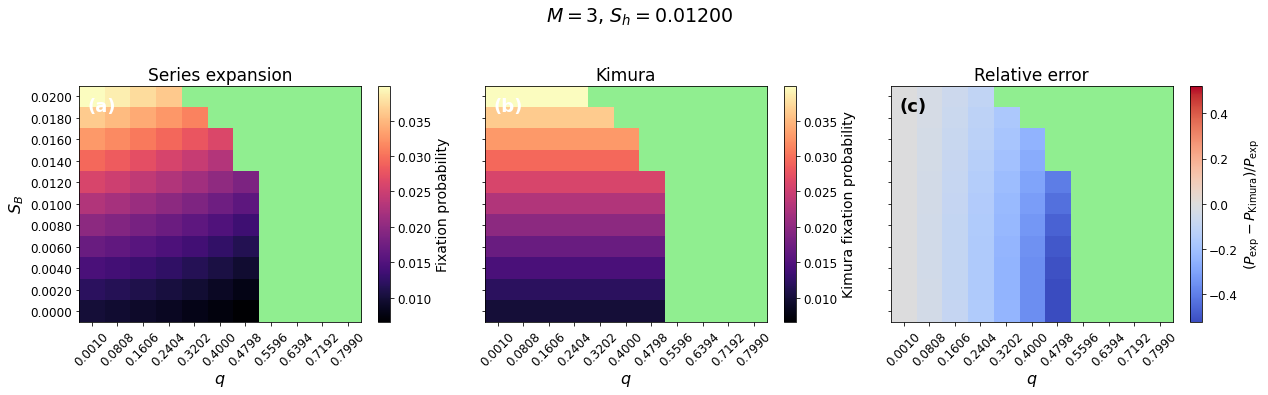


Requested (M, S_h) = (6, 0.012000); using (M, S_h) = (6, 0.012000)
Saved: data_fix_prob/three_heatmaps_over_SB_q_M_6_Sh_0.01200.pdf


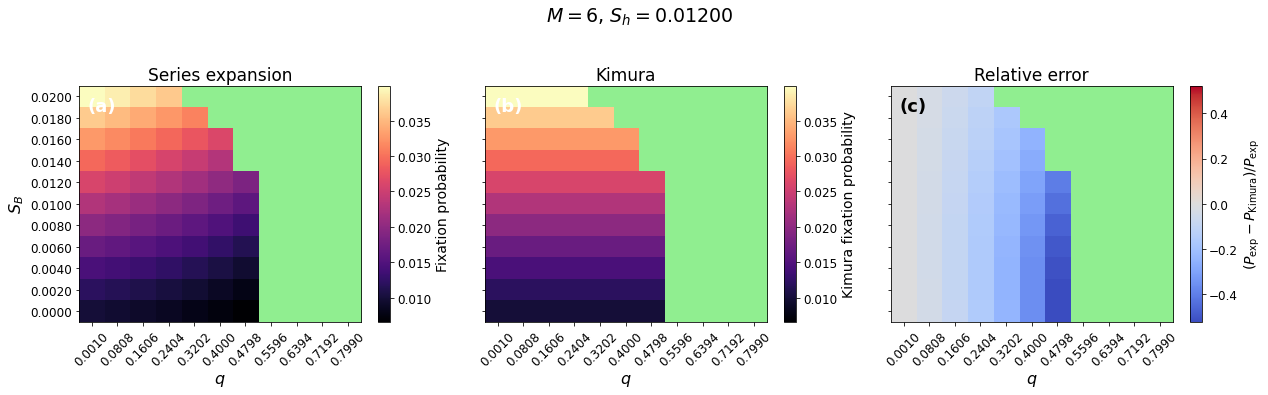


Requested (M, S_h) = (9, 0.012000); using (M, S_h) = (9, 0.012000)
Saved: data_fix_prob/three_heatmaps_over_SB_q_M_9_Sh_0.01200.pdf


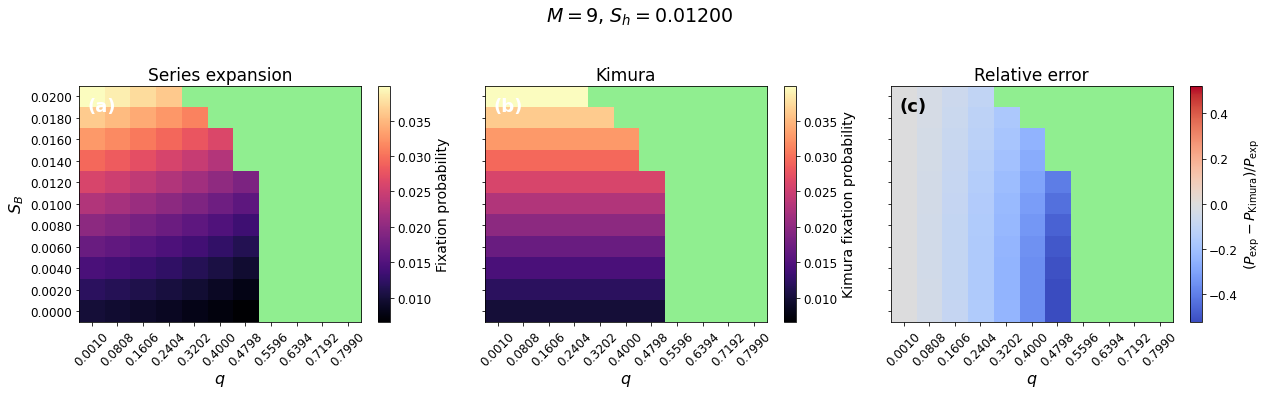

In [87]:
# User-chosen values of (M, S_h)
M_Sh_to_plot = [
    (3,  0.012),
    (6, 0.012),
    (9, 0.012),
]

results_SB_q = {}

for M_requested, Sh_requested in M_Sh_to_plot:
    res = plot_fixed_M_Sh_over_SB_q(
        M_requested=M_requested,
        Sh_requested=Sh_requested,
        save=True
    )
    results_SB_q[(res["M"], res["Sh"])] = res


#debug
#print(results_SB_q[(20, Shsets[nearest_index(0.010, Shsets)])]["heatmap_exp"])
#print("===================")
#print(results_SB_q[(20, Shsets[nearest_index(0.010, Shsets)])]["heatmap_kim"])



Requested (M, S_B) = (3, 0.008000); using (M, S_B) = (3, 0.008000)
Saved: data_fix_prob/three_heatmaps_over_Sh_q_M_3_SB_0.00800.pdf


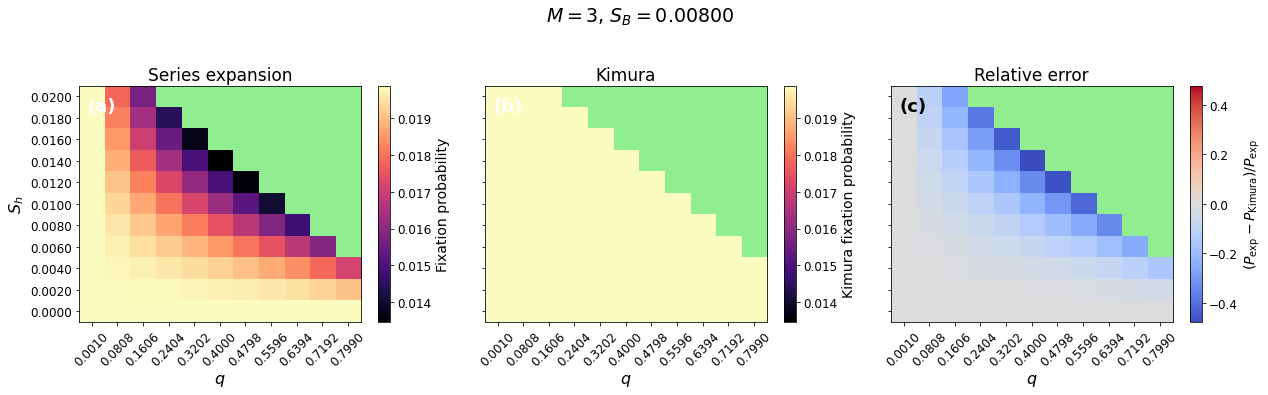


Requested (M, S_B) = (3, 0.012000); using (M, S_B) = (3, 0.012000)
Saved: data_fix_prob/three_heatmaps_over_Sh_q_M_3_SB_0.01200.pdf


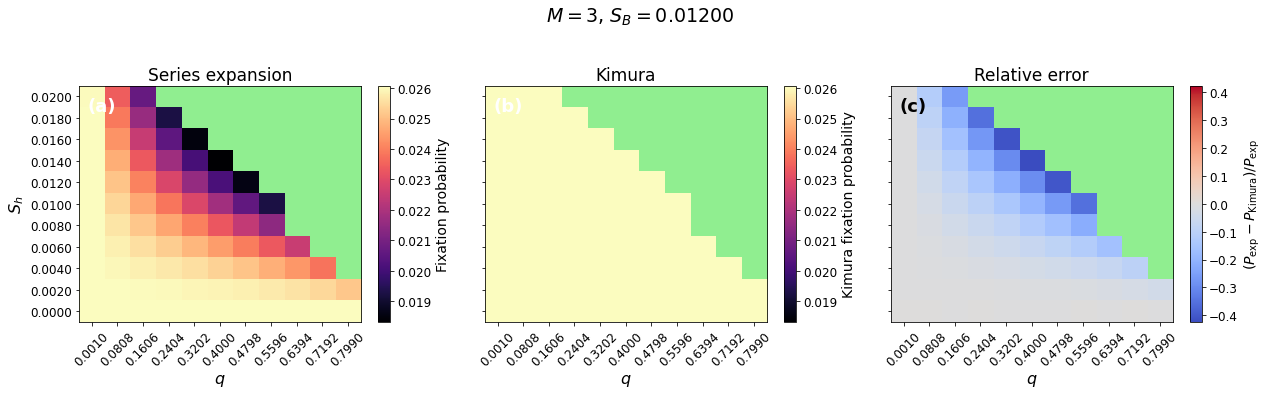


Requested (M, S_B) = (3, 0.016000); using (M, S_B) = (3, 0.016000)
Saved: data_fix_prob/three_heatmaps_over_Sh_q_M_3_SB_0.01600.pdf


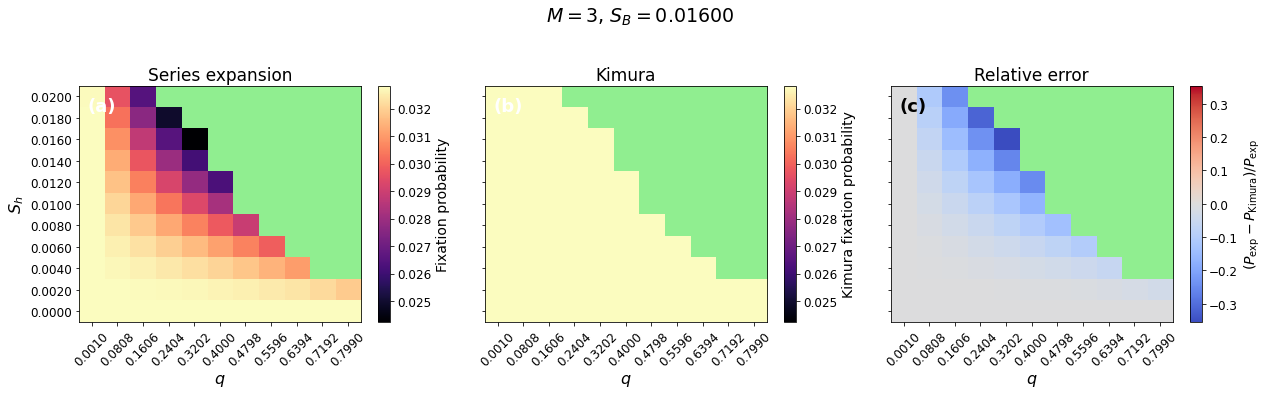

In [137]:
# User-chosen values of (M, S_B)
M_SB_to_plot = [
    (3, 0.008),
    (3, 0.012),
    (3, 0.016),
]

results_Sh_q = {}

for M_requested, SB_requested in M_SB_to_plot:
    res = plot_fixed_M_SB_over_Sh_q(
        M_requested=M_requested,
        SB_requested=SB_requested,
        save=True
    )
    results_Sh_q[(res["M"], res["SB"])] = res



Requested (M, S_h) = (3, 0.004000); using (M, S_h) = (3, 0.004000)

Requested (M, S_h) = (3, 0.010000); using (M, S_h) = (3, 0.010000)

Requested (M, S_h) = (3, 0.016000); using (M, S_h) = (3, 0.016000)
Saved: data_fix_prob/three_heatmaps_over_SB_q_MULTI_K3.pdf


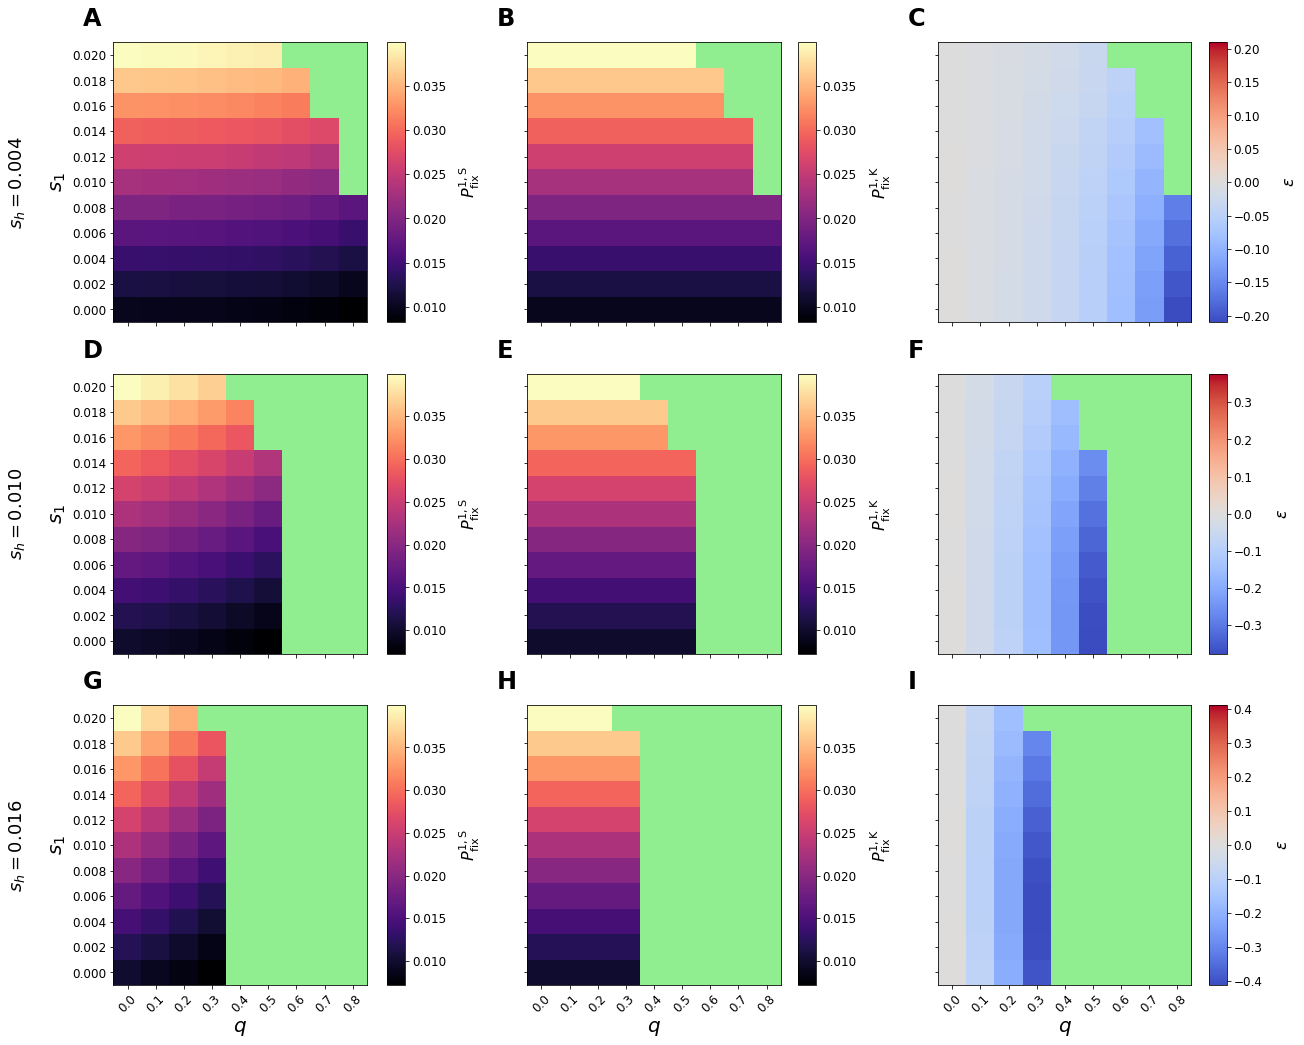

In [189]:
# User-chosen values of (M, S_h)
M_Sh_to_plot = [
    (3, 0.004),
    (3, 0.010),
    (3, 0.016),
]

results_SB_q = plot_fixed_M_Sh_over_SB_q_combined(
    M_Sh_requested_array=M_Sh_to_plot,
    save=True
)


Requested (M, S_B) = (3, 0.004000); using (M, S_B) = (3, 0.004000)

Requested (M, S_B) = (3, 0.010000); using (M, S_B) = (3, 0.010000)

Requested (M, S_B) = (3, 0.016000); using (M, S_B) = (3, 0.016000)
Saved: data_fix_prob/three_heatmaps_over_Sh_q_MULTI_K3.pdf


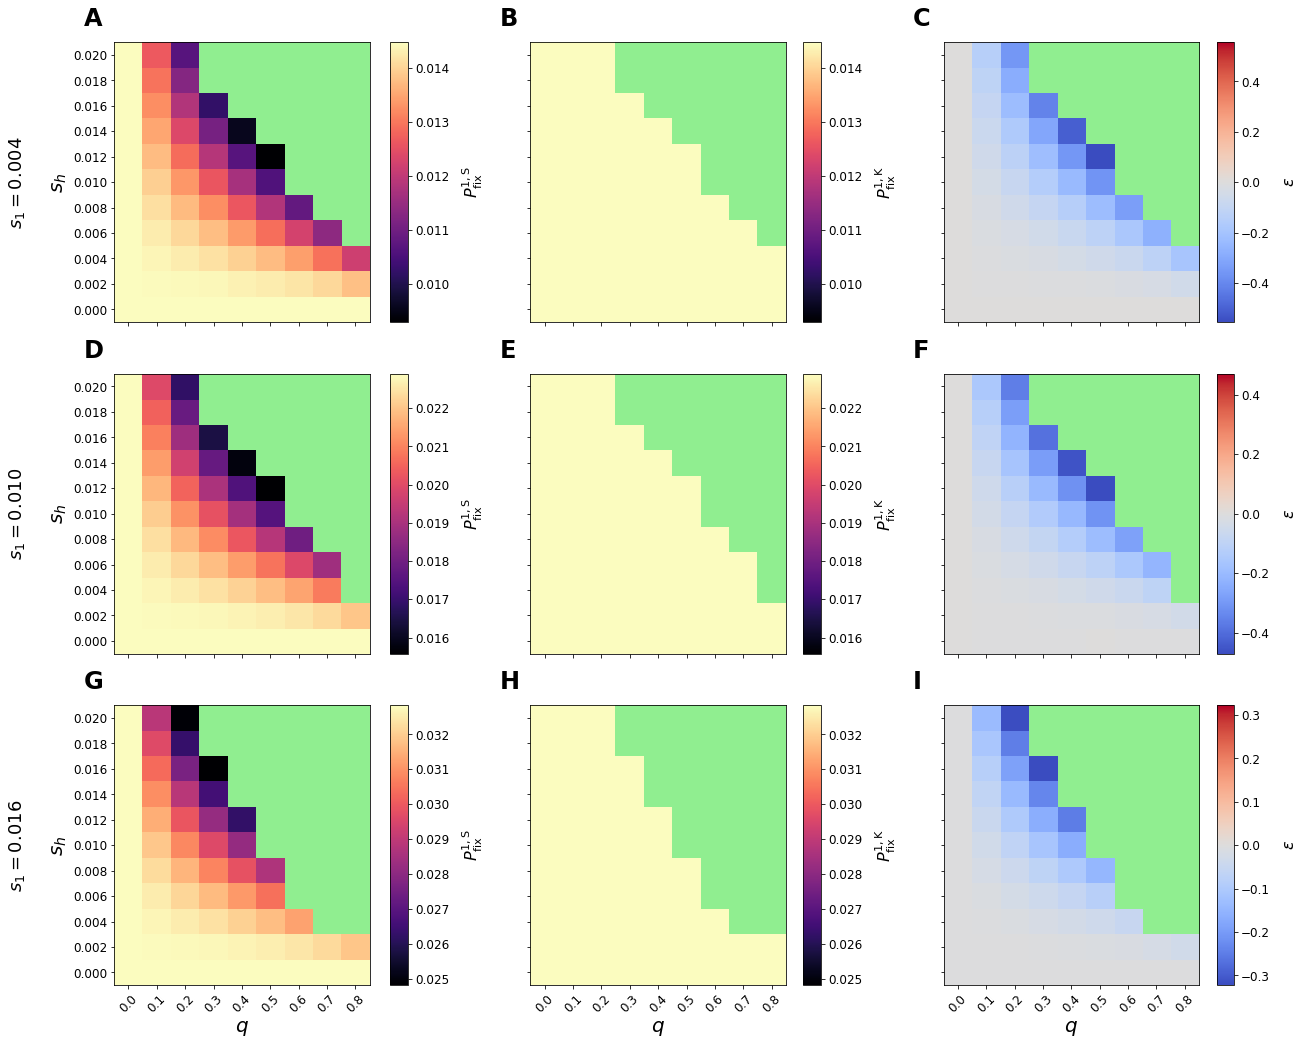

In [190]:
# User-chosen values of (M, S_B)
M_SB_to_plot = [
    (3, 0.004),
    (3, 0.010),
    (3, 0.016),
]

results_Sh_q = plot_fixed_M_SB_over_Sh_q_combined(
    M_SB_requested_array=M_SB_to_plot,
    save=True
)

In [13]:
D = 10
SMAX = 0.02

print(np.linspace(0.0, SMAX, num=D))

[0.         0.00222222 0.00444444 0.00666667 0.00888889 0.01111111
 0.01333333 0.01555556 0.01777778 0.02      ]
